In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from sklearn.linear_model import Lasso, Ridge, LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
import warnings
from sklearn.exceptions import ConvergenceWarning   # For part D4 so it will run
warnings.simplefilter("ignore", ConvergenceWarning)
import seaborn as sns

# ==============================================================================

import plot_params
from config import SEED, FIGURES_PATH, RESULTS_PATH, DATA_PATH
from Data.data import load_mnist, train_val_split, one_hot, to_column
from Machine.network import NeuralNetwork
from Machine.optimizers import train
from Machine.metrics import (mse_score, accuracy, confusion_matrix, precision_recall_f1)
import utils as u       # Reused functions from Project 1

RERUN = False   # load saved results when they exist

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part b)** Neural network

</div>

Runge data from Project 1, with a validation split of the training data for
tuning

In [2]:
runge_x_train, runge_x_test, runge_y_train, runge_y_test = u.create_dataset()

# (n, 1) for the network and sklearn
runge_X_train, runge_X_test = to_column(runge_x_train), to_column(runge_x_test)
runge_Y_train, runge_Y_test = to_column(runge_y_train), to_column(runge_y_test)

# Split 25% of train set for validation
runge_X_fit, runge_X_val, runge_Y_fit, runge_Y_val = train_val_split(
    runge_X_train, runge_Y_train, val_size=0.25, seed=SEED, stratify=False)

OLS benchmark: best polynomial degree by k-fold CV on the training data

OLS: best degree 12 (CV MSE 0.0141), train MSE 0.0104, test MSE 0.0093


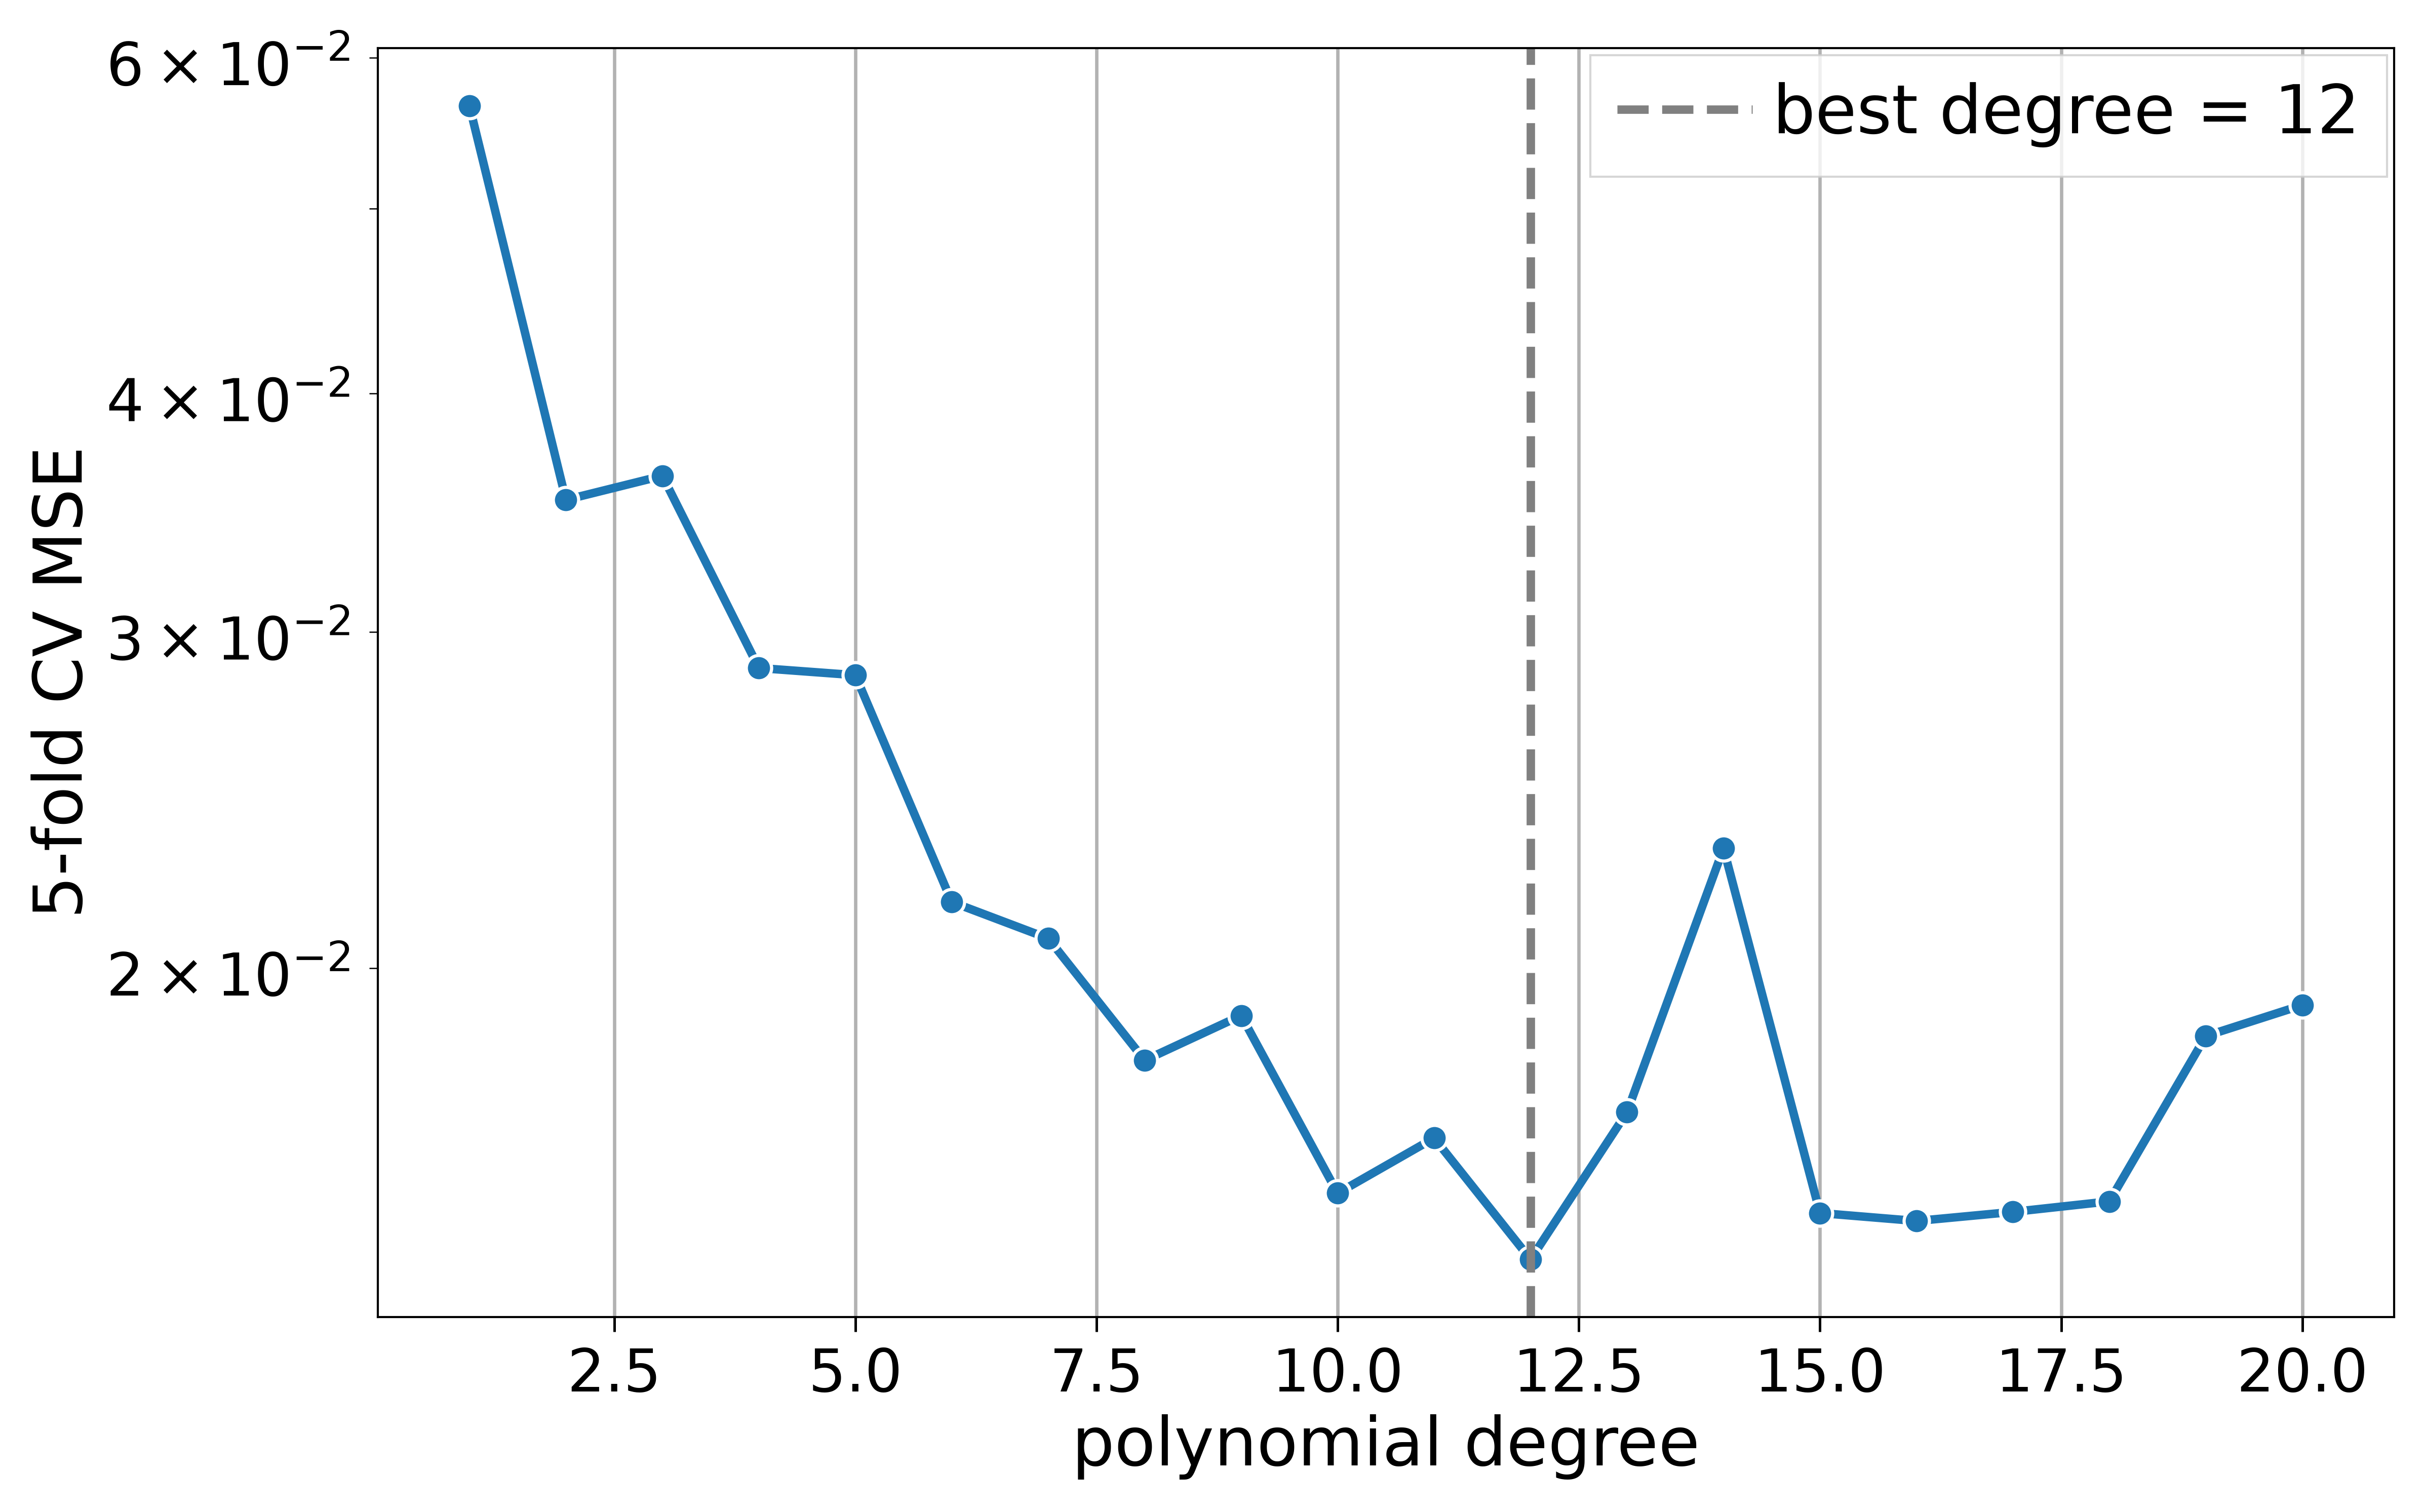

In [3]:
K = 5
MAX_DEGREE = 20

def compute_ols_cv():
    cv_mse = u.k_fold_degrees(runge_X_train, runge_y_train, K,
                          LinearRegression(), maxdegree=MAX_DEGREE)
    return {"cv_mse": cv_mse, "degrees": np.arange(1, MAX_DEGREE + 1)}

ols_cv = u.cached_arrays(RESULTS_PATH / "b_ols_cv.npz", compute_ols_cv, RERUN)
best_ols = u.best_cell(ols_cv["cv_mse"], degree=ols_cv["degrees"])
best_degree = int(best_ols["degree"])

# ==============================================================================

# Refit on whole training set, and look at test set once
ols_model = u.poly_model(best_degree, LinearRegression()).fit(runge_X_train, runge_y_train)
ols_train_mse = mse_score(runge_y_train, ols_model.predict(runge_X_train))
ols_test_mse = mse_score(runge_y_test, ols_model.predict(runge_X_test))
print(f"OLS: best degree {best_degree} (CV MSE {best_ols['value']:.4f}), "
      f"train MSE {ols_train_mse:.4f}, test MSE {ols_test_mse:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(x=ols_cv["degrees"], y=ols_cv["cv_mse"], marker="o", ax=ax)
ax.axvline(best_degree, ls="--", color="gray", label=f"best degree = {best_degree}")
ax.set(yscale="log", xlabel="polynomial degree", ylabel=f"{K}-fold CV MSE")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(FIGURES_PATH / "B-OLS_cv_degree.pdf")

Learning rate sweep

Best: SGD + RMSprop, gamma = 1.0e-01, val MSE 0.0144


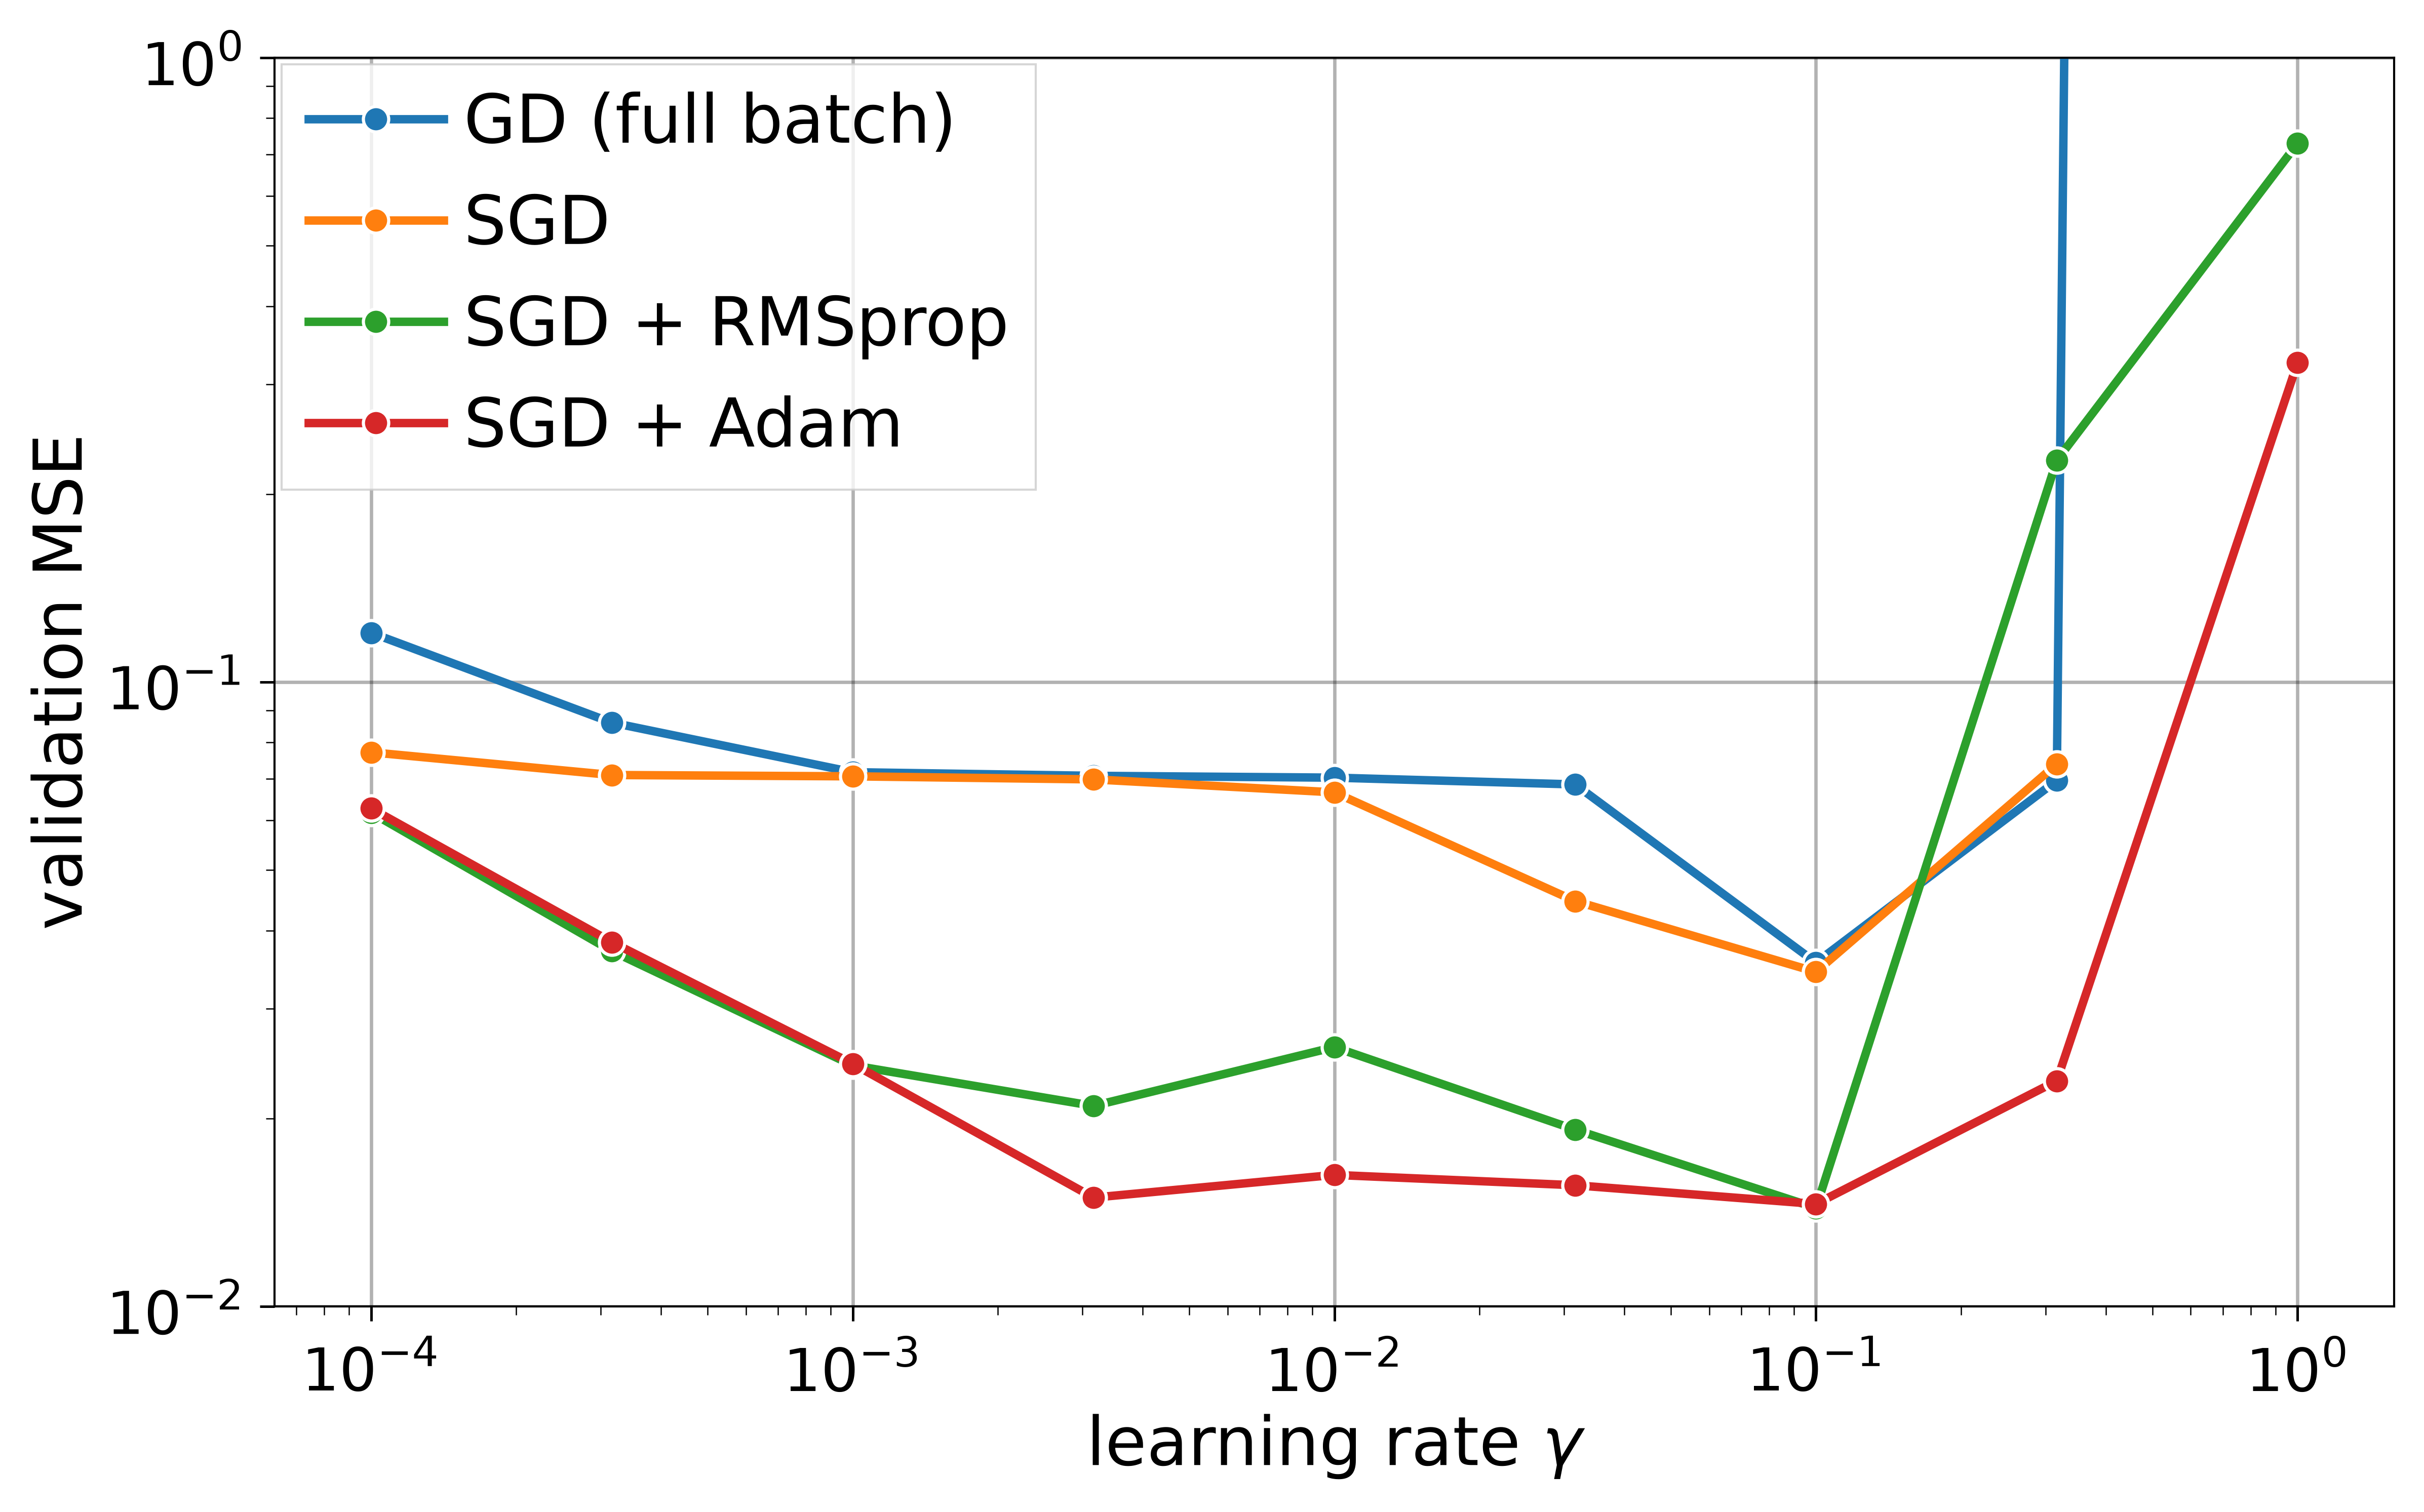

In [4]:
OPTIMIZERS = {                        # label: (model, batch size)
    "GD (full batch)": ("plain", None),
    "SGD": ("plain", 10),
    "SGD + RMSprop": ("rmsprop", 10),
    "SGD + Adam": ("adam", 10)
}
LEARNING_RATES = np.geomspace(1e-4, 1.0, 9)
EPOCHS_B = 1000

def compute_lr_sweep():
    val_mse = np.full((len(OPTIMIZERS), len(LEARNING_RATES)), np.nan)
    for i, (method, batch_size) in enumerate(OPTIMIZERS.values()):
        for j, gamma in enumerate(LEARNING_RATES):
            net = NeuralNetwork([1, 50, 1], ["sigmoid", "identity"], "mse", seed=SEED)
            with np.errstate(all="ignore"):
                train(net, runge_X_fit, runge_Y_fit, method=method, gamma=gamma,
                      epochs=EPOCHS_B, batch_size=batch_size, seed=SEED)
                val_mse[i, j] = mse_score(runge_Y_val, net.predict(runge_X_val))
    return {"val_mse": val_mse, "gammas" : LEARNING_RATES}

lr_sweep = u.cached_arrays(RESULTS_PATH / "b_lr_sweep.npz", compute_lr_sweep, RERUN)
best_b = u.best_cell(lr_sweep["val_mse"], optimizer=list(OPTIMIZERS), gamma=lr_sweep["gammas"])
print(f"Best: {best_b['optimizer']}, gamma = {best_b['gamma']:.1e}, val MSE {best_b['value']:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
for label, curve in zip(OPTIMIZERS, lr_sweep["val_mse"]):
    sns.lineplot(x=lr_sweep["gammas"], y=curve, label=label, marker="o", ax=ax)
ax.set(xscale="log", yscale="log", ylim=(1e-2, 1.0),
       xlabel=r"learning rate $\gamma$", ylabel="validation MSE")
ax.grid(alpha=0.3)
fig.savefig(FIGURES_PATH / "B-learning_rate_sweep.pdf")

Architectures: for each, pick $\gamma$ on the validation set, retrain on the
full training set, then evaluate once on the test set

In [5]:
ARCHITECTURES = {               # label: layer sizes [input, hiden..., output]
    "1 x 50":   [1, 50, 1],
    "1 x 500":  [1, 500, 1],
    "2 x 50":   [1, 50, 50, 1],
    "2 x 100":  [1, 100, 100, 1]
}
# Best optimizer from the learning-rate sweep
best_method, best_batch_size = OPTIMIZERS[best_b["optimizer"]]

# Dense grid on the standardizes coordinates, to draw smooth curves
runge_x_raw, runge_y_raw = u.create_dataset(split=False, rescale=False)
grid_x = np.linspace(-1, 1, 400)
grid_x_std = (grid_x - runge_x_raw.mean()) / runge_x_raw.std()
runge_true_curve = 1 / (1 + 25 * grid_x**2) - runge_y_raw.mean()

def compute_architectures():
    n_arch = len(ARCHITECTURES)
    best_gammas, train_mse, test_mse = np.zeros(n_arch), np.zeros(n_arch), np.zeros(n_arch)
    curves = np.zeros((n_arch, len(grid_x_std)))
    for i, sizes in enumerate(ARCHITECTURES.values()):
        acts = ["sigmoid"] * (len(sizes) - 2) + ["identity"]
        
        # 1: choose gamma on the validation set
        val_mse = np.full(len(LEARNING_RATES), np.nan)
        for j, gamma in enumerate(LEARNING_RATES):
            net = NeuralNetwork(sizes, acts, "mse", seed=SEED)
            with np.errstate(all="ignore"):
                train(net, runge_X_fit, runge_Y_fit, method=best_method, gamma=gamma, 
                      epochs=EPOCHS_B, batch_size=best_batch_size, seed=SEED)
                val_mse[j] = mse_score(runge_Y_val, net.predict(runge_X_val))
        best_gammas[i] = u.best_cell(val_mse, gamma=LEARNING_RATES)["gamma"]
        
        # 2: retrain on the whole training set, then look at test set once
        net = NeuralNetwork(sizes, acts, "mse", seed=SEED)
        train(net, runge_X_train, runge_Y_train, method=best_method, gamma=best_gammas[i],
              epochs=EPOCHS_B, batch_size=best_batch_size, seed=SEED)
        train_mse[i] = mse_score(runge_Y_train, net.predict(runge_X_train))
        test_mse[i] = mse_score(runge_Y_test, net.predict(runge_X_test))
        curves[i] = net.predict(to_column(grid_x_std)).ravel()
    return {"best_gammas": best_gammas, "train_mse": train_mse, "test_mse": test_mse, "curves": curves}

arch_results = u.cached_arrays(RESULTS_PATH / "b_architectures.npz", compute_architectures, RERUN)

Results table and fitted curves, for OLS vs the four networks

model             gamma  train MSE  test MSE
OLS deg 12                  0.0104    0.0093
NN 1 x 50       1.0e-01     0.0148    0.0154
NN 1 x 500      1.0e-01     0.0114    0.0119
NN 2 x 50       1.0e-03     0.0112    0.0112
NN 2 x 100      1.0e-02     0.0100    0.0188


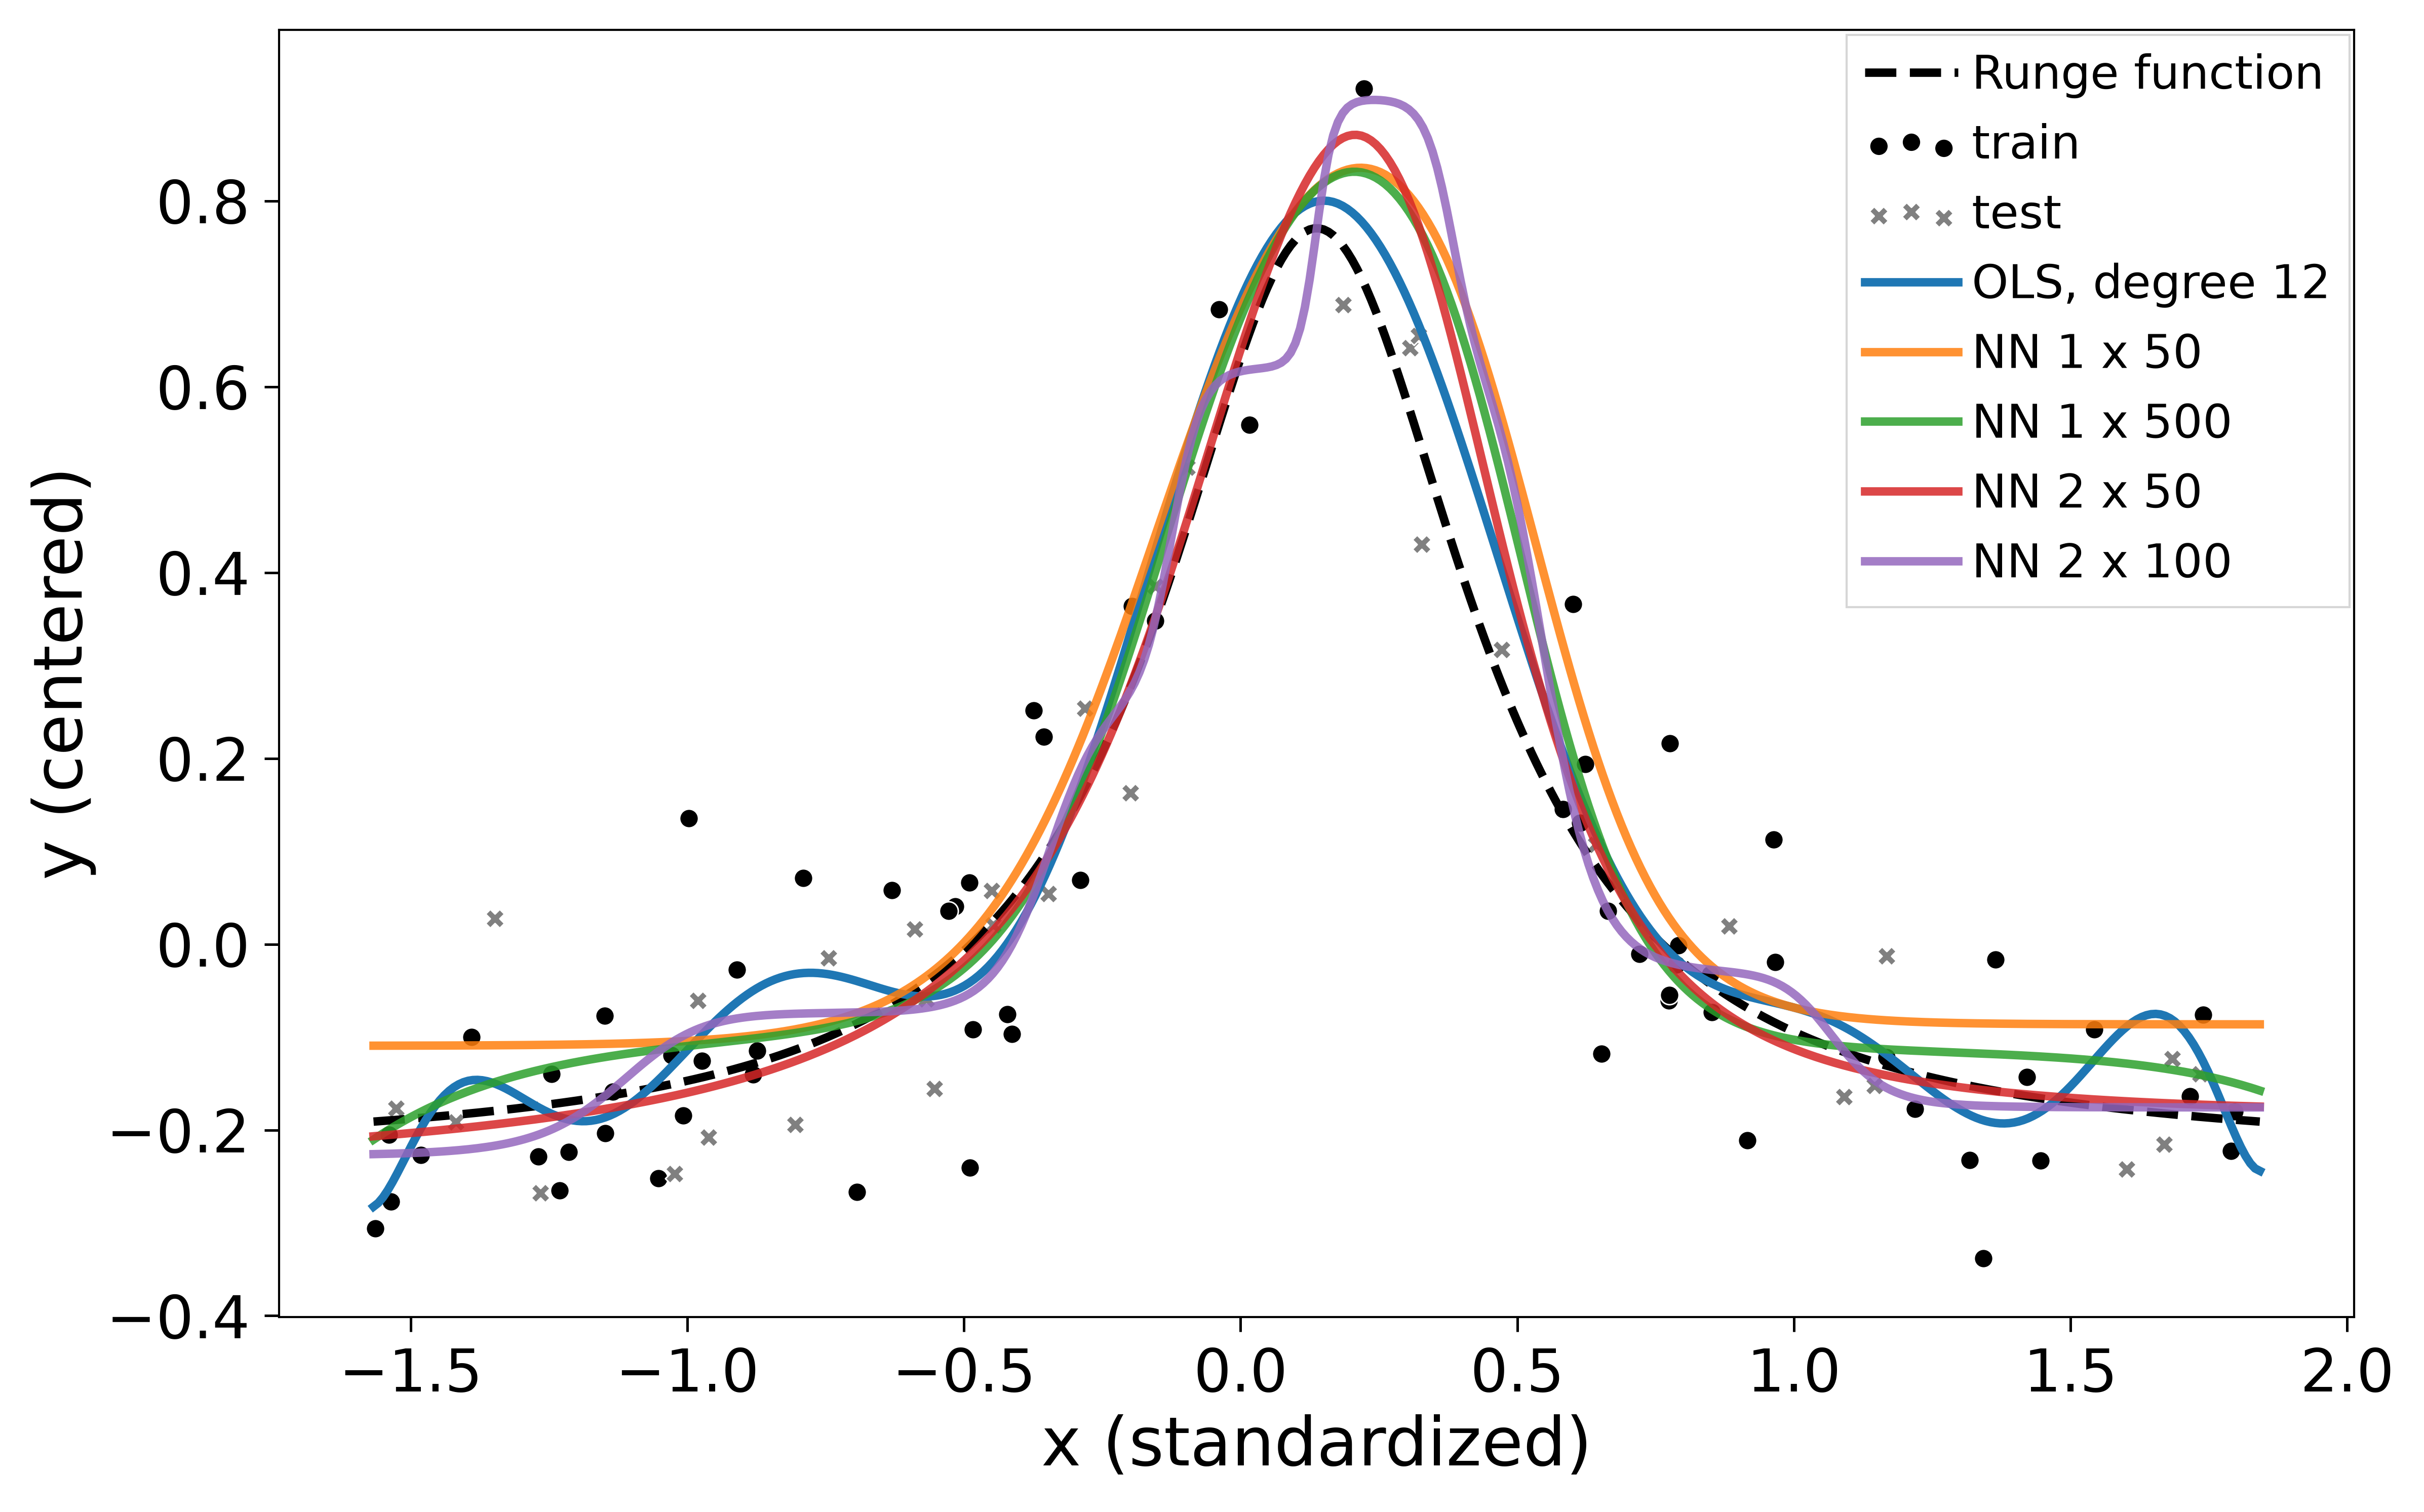

In [6]:
ols_curve = ols_model.predict(grid_x_std.reshape(-1, 1))

print(f"{'model':<14}{'gamma':>9}{'train MSE':>11}{'test MSE':>10}")
print(f"{'OLS deg ' + str(best_degree):<14}{'':>9}{ols_train_mse:>11.4f}{ols_test_mse:>10.4f}")
for label, gamma, tr, te in zip(ARCHITECTURES, arch_results["best_gammas"],
                                arch_results["train_mse"], arch_results["test_mse"]):
    print(f"{'NN ' + label:<14}{gamma:>9.1e}{tr:>11.4f}{te:>10.4f}")
    
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(grid_x_std, runge_true_curve, "k--", label="Runge function")
sns.scatterplot(x=runge_x_train, y=runge_y_train, s=20, color="k", label="train", ax=ax)
sns.scatterplot(x=runge_x_test, y=runge_y_test, s=20, color="gray", marker="X", label="test", ax=ax)
sns.lineplot(x=grid_x_std, y=ols_curve, label=f"OLS, degree {best_degree}", ax=ax)
for label, curve in zip(ARCHITECTURES, arch_results["curves"]):
    sns.lineplot(x=grid_x_std, y=curve, label=f"NN {label}", alpha=0.85, ax=ax)
ax.set(xlabel="x (standardized)", ylabel="y (centered)")
ax.legend(loc="upper right", fontsize=11)
fig.savefig(FIGURES_PATH / "B-NN_vs_OLS_fits.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part c)** Activation functions and depths

</div>

Sweep over activation, depth and $\gamma$, ran over several seeds

In [7]:
ACTIVATIONS = ["sigmoid", "relu", "leaky_relu"]
DEPTHS = [1, 2, 3, 4]                   # number of hidden layers
WIDTHS = [10, 25, 50, 100]              # nodes per hidden layer
GAMMAS_C = np.geomspace(1e-3, 1.0, 4)
SEEDS_C = [0, 1, 2]                     # average over initializations
EPOCHS_C = 500

def run_one_runge(activation, depth, width, gamma, seed):
    '''Train one network on the fit set, then return its final train and validation MSE'''
    sizes = [1] + [width] * depth + [1]
    acts = [activation] * depth + ["identity"]
    net = NeuralNetwork(sizes, acts, "mse", seed=seed)
    history = train(net, runge_X_fit, runge_Y_fit, method="rmsprop", gamma=gamma,
                    epochs=EPOCHS_C, batch_size=10, seed=seed,
                    X_val=runge_X_val, Y_val=runge_Y_val)
    return history["train_cost"][-1], history["val_cost"][-1]


def compute_depth_width_sweep():
    shape = (len(ACTIVATIONS), len(DEPTHS), len(WIDTHS), len(GAMMAS_C), len(SEEDS_C))
    train_mse = np.full(shape, np.nan)          # Nan marks diverged runs
    val_mse = np.full(shape, np.nan)
    for a, d, w, g, s in np.ndindex(shape):     # loop over every grid point
        with np.errstate(all="ignore"):
            train_cost, val_cost = run_one_runge(ACTIVATIONS[a], DEPTHS[d], WIDTHS[w],
                                                 GAMMAS_C[g], SEEDS_C[s])
        if np.isfinite(train_cost) and np.isfinite(val_cost):
            train_mse[a, d, w, g, s], val_mse[a, d, w, g, s] = train_cost, val_cost
    return {"train_mse": train_mse, "val_mse": val_mse}

depth_width = u.cached_arrays(RESULTS_PATH / "c_depth_width.npz", compute_depth_width_sweep, RERUN)

Best $\gamma$ for every (activation, depth, width), shown as heat maps.
The overall winner is stored in `best_c`.

Overall best: relu, depth 4, width 25, gamma 1e-03, val MSE 0.0142
---------------------------------------------------------------
sigmoid    best: depth 3, width 50, gamma 1e-03, val MSE 0.0144
relu       best: depth 4, width 25, gamma 1e-03, val MSE 0.0142
leaky_relu best: depth 3, width 10, gamma 1e-03, val MSE 0.0148


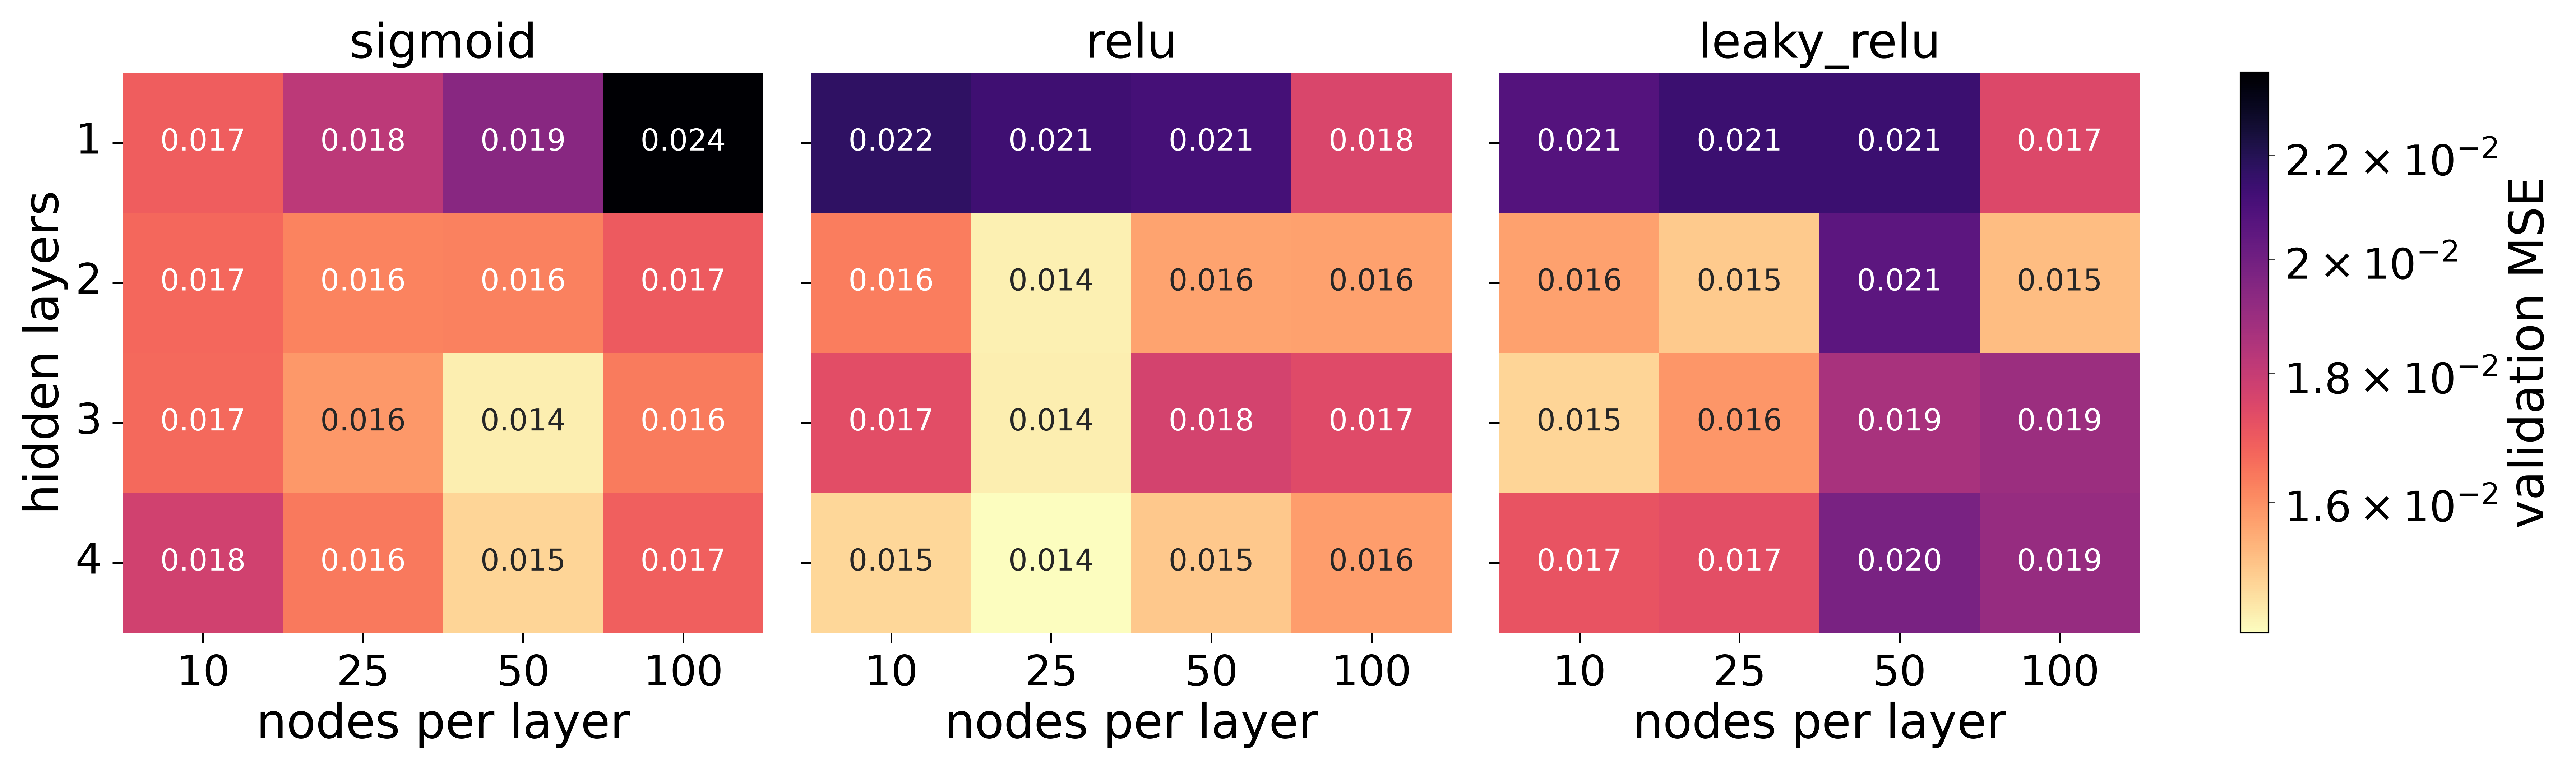

In [8]:
val_mse_mean = depth_width["val_mse"].mean(axis=-1)     # average over seeds
best_c = u.best_cell(val_mse_mean, activation=ACTIVATIONS, depth=DEPTHS,
                     width=WIDTHS, gamma=GAMMAS_C)
print(f"Overall best: {best_c['activation']}, depth {best_c['depth']}, "
      f"width {best_c['width']}, gamma {best_c['gamma']:.0e}, val MSE {best_c['value']:.4f}")
print("---------------------------------------------------------------")
for a, activation in enumerate(ACTIVATIONS):
      best = u.best_cell(val_mse_mean[a], depth=DEPTHS, width=WIDTHS, gamma=GAMMAS_C)
      print(f"{activation:10s} best: depth {best['depth']}, width {best['width']}, "
            f"gamma {best['gamma']:.0e}, val MSE {best['value']:.4f}")

# Best gamma in every (activation, depth, width) cell
finite_val = np.where(np.isfinite(val_mse_mean), val_mse_mean, np.inf)
val_mse_best_gamma = finite_val.min(axis=-1)
val_mse_best_gamma[np.isinf(val_mse_best_gamma)] = np.nan

heat_min, heat_max = np.nanmin(val_mse_best_gamma), min(np.nanmax(val_mse_best_gamma), 1.0)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, activation, grid in zip(axes, ACTIVATIONS, val_mse_best_gamma):
      sns.heatmap(grid, ax=ax, cmap="magma_r", norm=LogNorm(heat_min, heat_max),
                  annot=True, fmt=".3f", cbar=False,
                  xticklabels=WIDTHS, yticklabels=DEPTHS)
      ax.set(title=activation, xlabel="nodes per layer")
      ax.tick_params(axis="y", rotation=0)
axes[0].set_ylabel("hidden layers")
fig.colorbar(axes[0].collections[0], ax=axes, label="validation MSE")
fig.savefig(FIGURES_PATH / "C-activation_depth_width.pdf")

Overfitting: train a long run of the biggest network per activation and compare
train and validation MSE

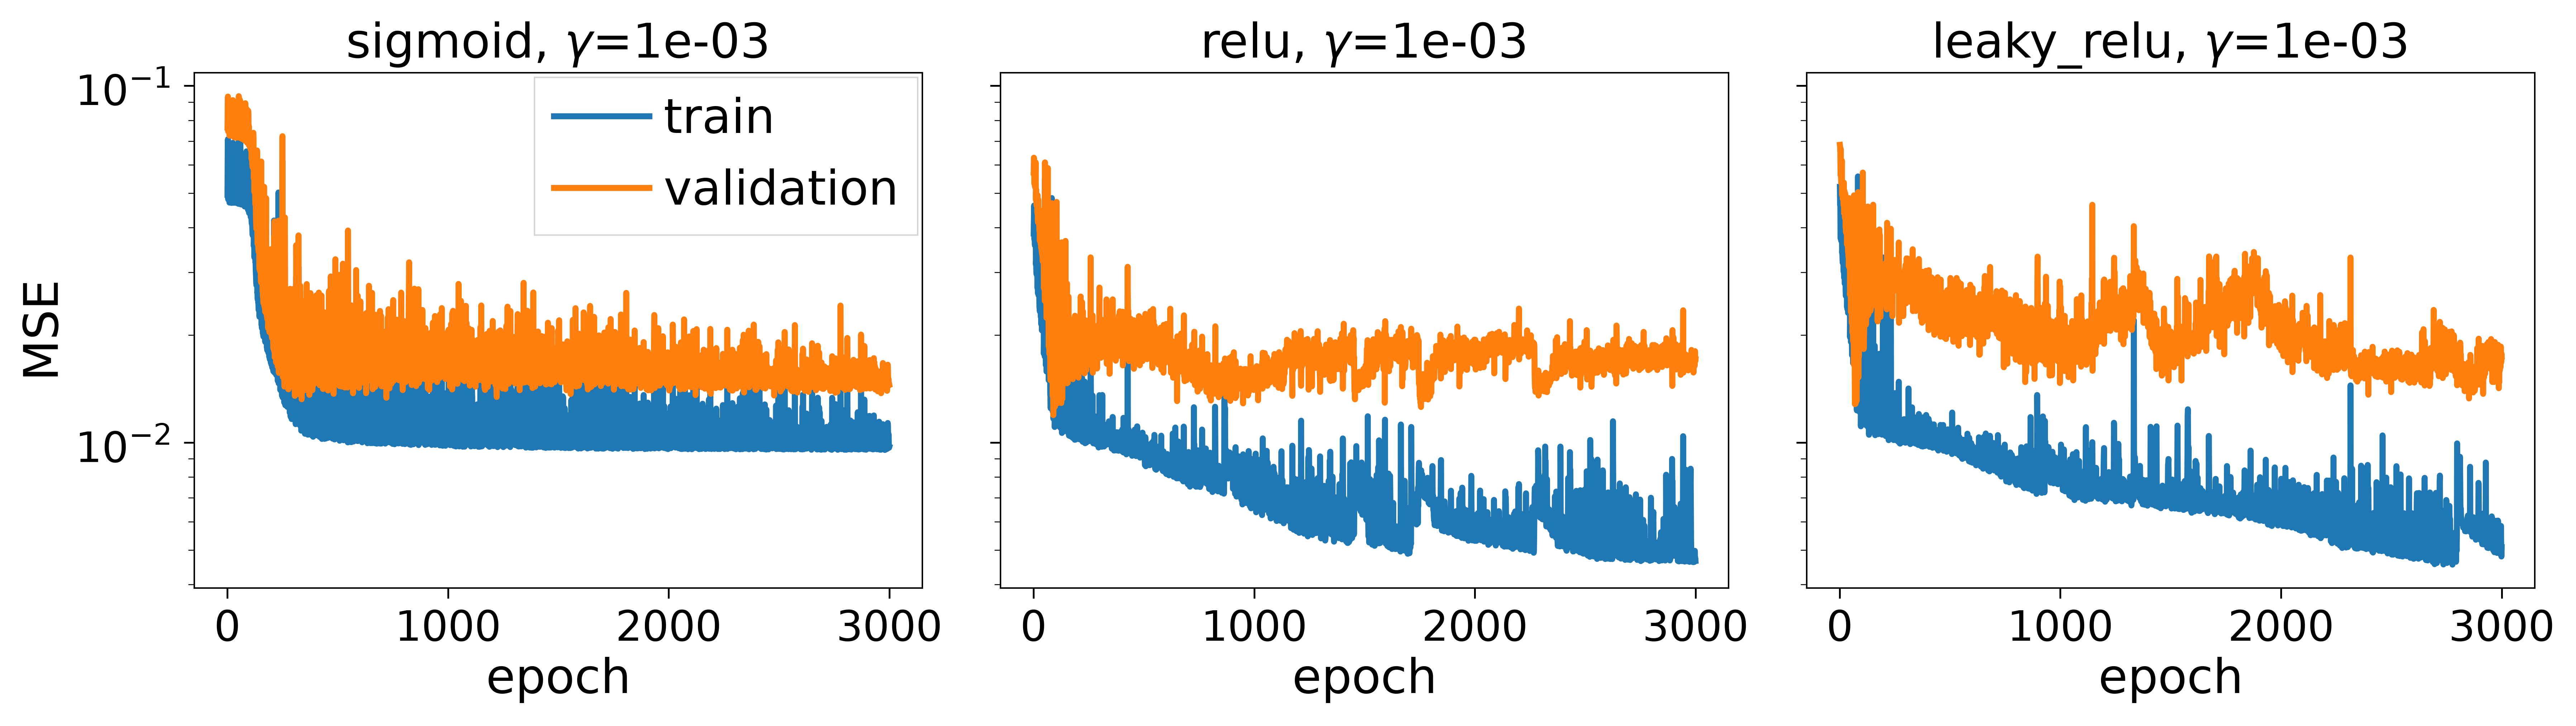

In [9]:
EPOCHS_OVERFIT = 3000

def compute_overfitting_curves():
    n_act = len(ACTIVATIONS)
    train_curves, val_curves = np.full((n_act, EPOCHS_OVERFIT), np.nan), np.full((n_act, EPOCHS_OVERFIT), np.nan)
    gammas = np.zeros(n_act)
    for a, activation in enumerate(ACTIVATIONS):
        gammas[a] = GAMMAS_C[0]     # 1e-3 for all activations, so the panels are comparable
        net = NeuralNetwork([1] + [WIDTHS[-1]] * DEPTHS[-1] + [1],
                            [activation] * DEPTHS[-1] + ["identity"], "mse", seed=SEED)
        with np.errstate(all="ignore"):
            history = train(net, runge_X_fit, runge_Y_fit, method="rmsprop", gamma=gammas[a],
                            epochs=EPOCHS_OVERFIT, batch_size=10, seed=SEED,
                            X_val=runge_X_val, Y_val=runge_Y_val)
        train_curves[a], val_curves[a] = history["train_cost"], history["val_cost"]
    return {"train_curves": train_curves, "val_curves": val_curves, "gammas": gammas}

overfit = u.cached_arrays(RESULTS_PATH / "c_overfitting_curves.npz", compute_overfitting_curves, RERUN)

epochs = np.arange(1, EPOCHS_OVERFIT + 1)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, activation, train_curve, val_curve, gamma in zip(
        axes, ACTIVATIONS, overfit["train_curves"], overfit["val_curves"], overfit["gammas"]):
    sns.lineplot(x=epochs, y=train_curve, label="train", ax=ax)
    sns.lineplot(x=epochs, y=val_curve, label="validation", ax=ax)
    ax.set(yscale="log", title=f"{activation}, $\\gamma$={gamma:.0e}", xlabel="epoch")
for ax in axes[1:]:
    ax.get_legend().remove()        # one legend is enough
axes[0].set_ylabel("MSE")
fig.savefig(FIGURES_PATH / "C-train_val_curves.pdf")

Vanishing gradients: gradient norm per layer at initialization in a deep network

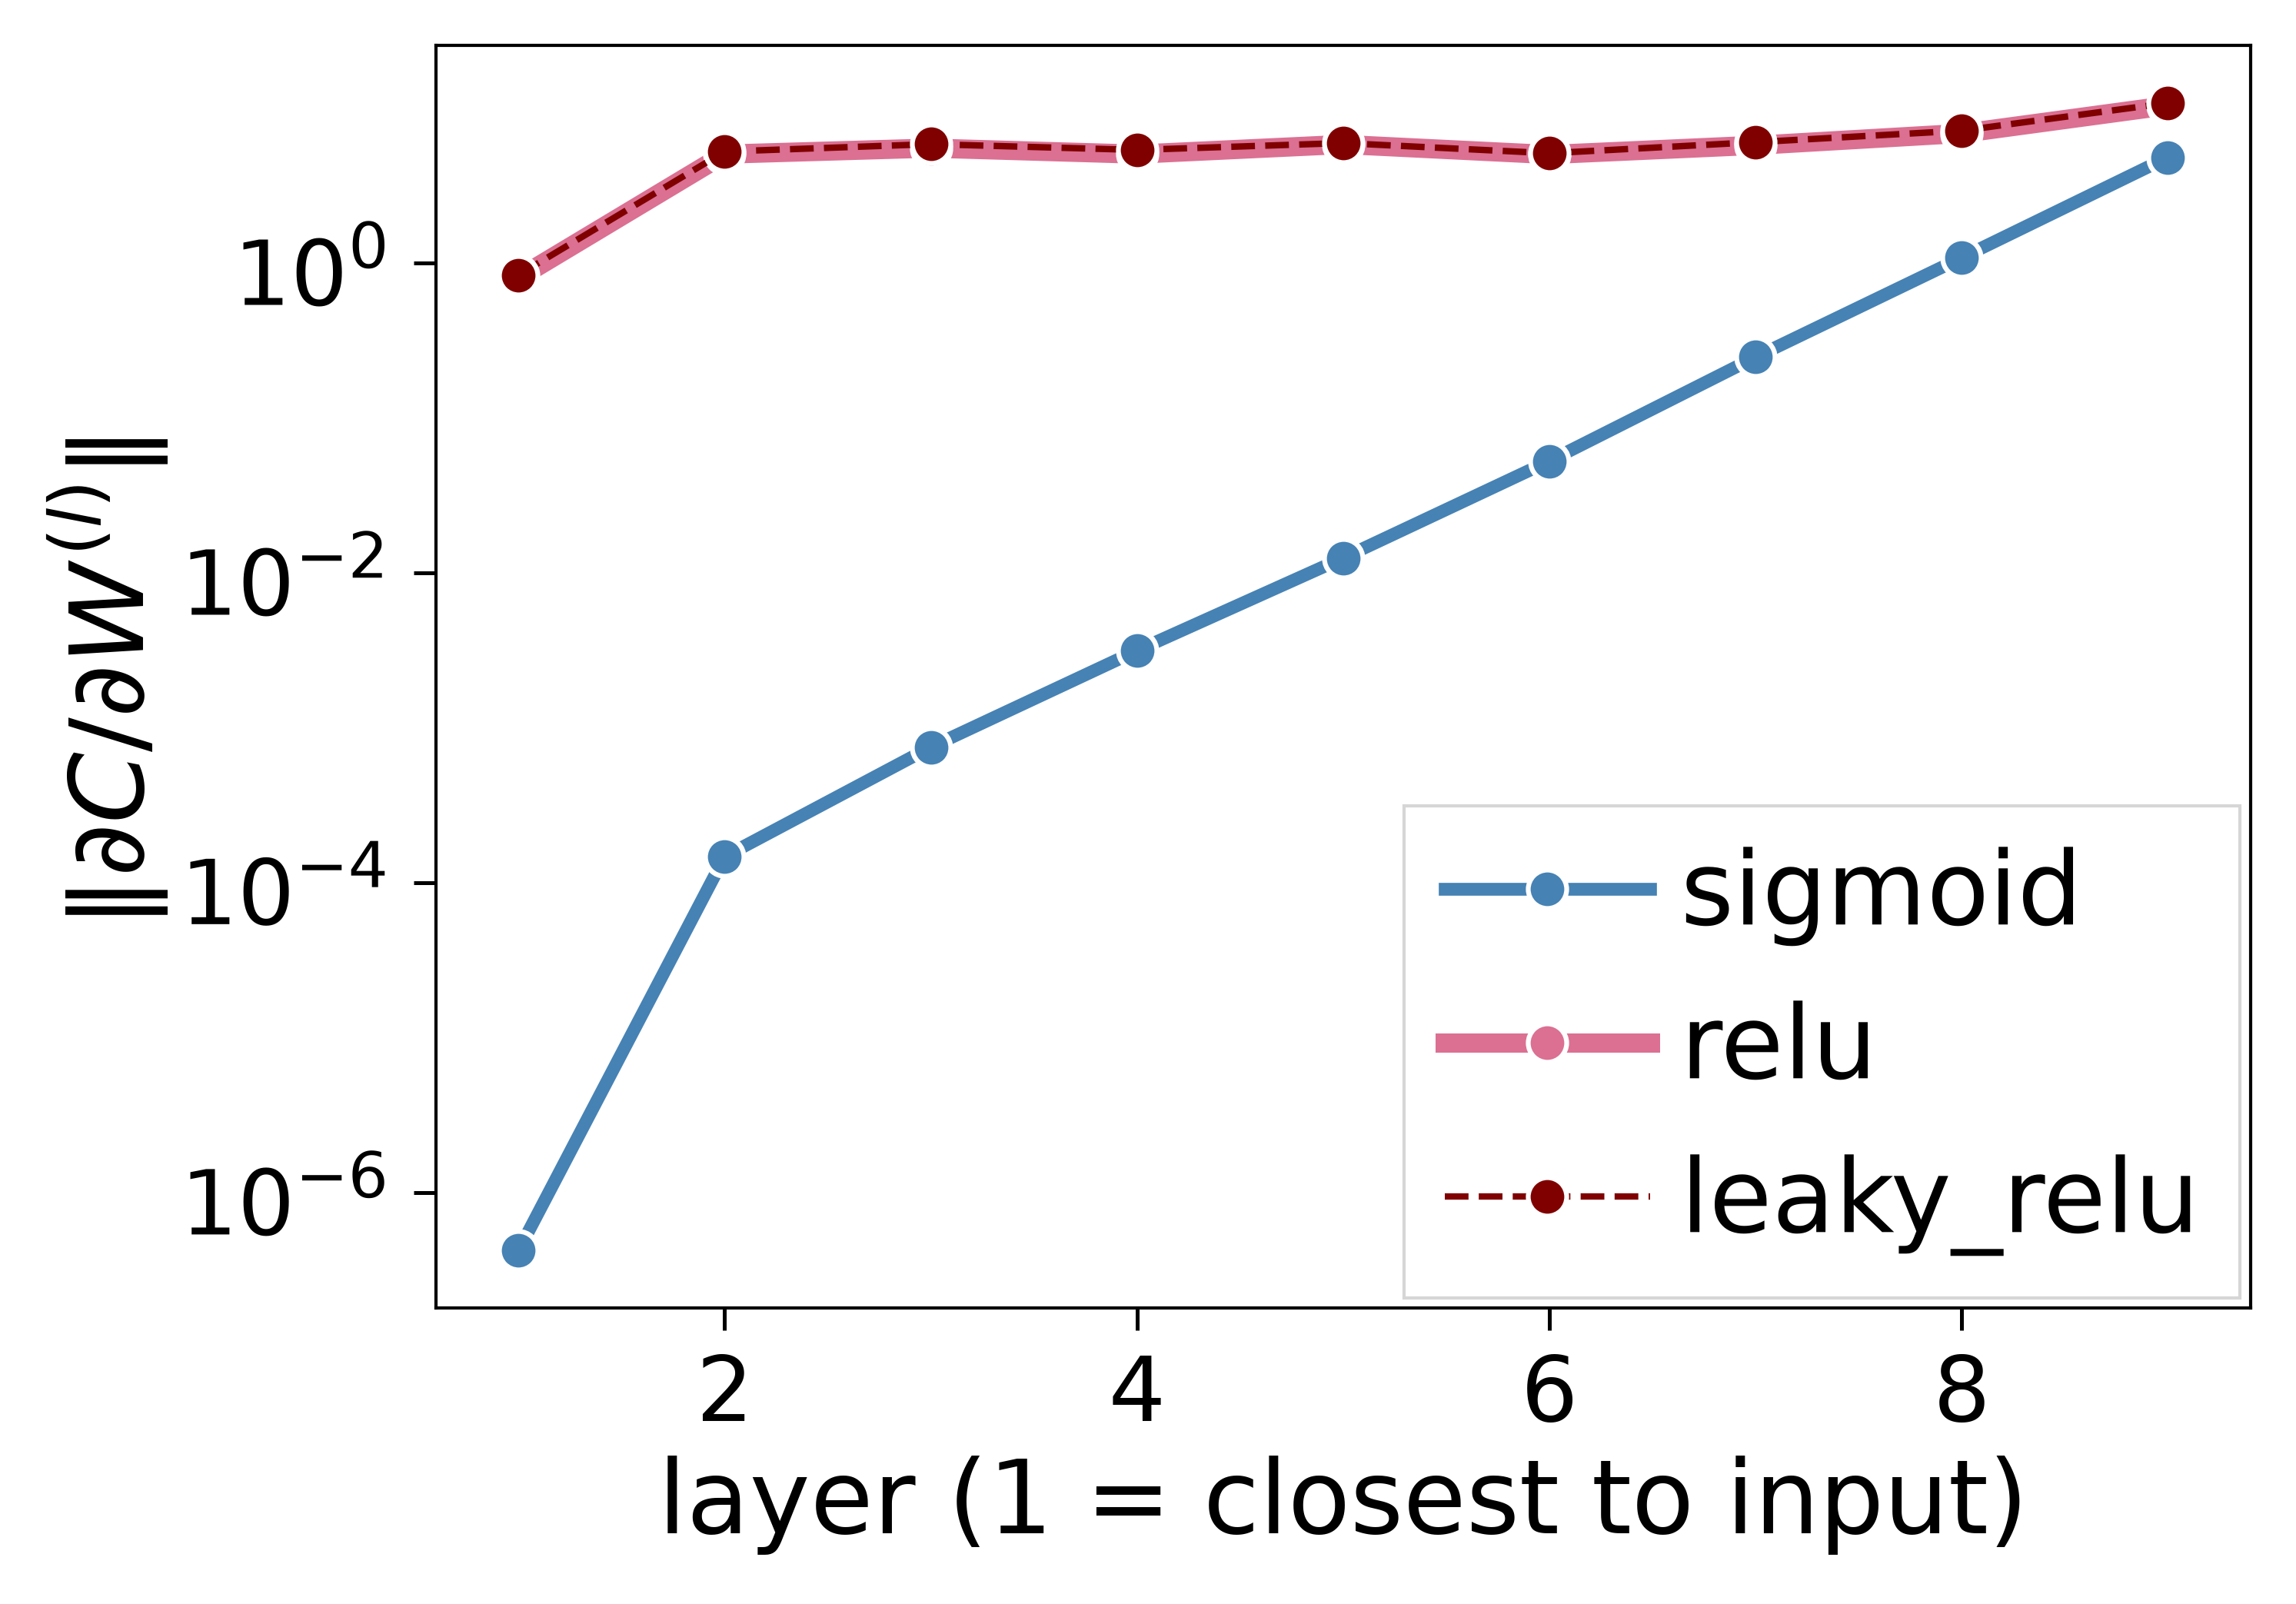

In [10]:
def layer_grad_norms(activation, depth=8, width=50, seed=SEED):
    '''Norm of dC/dW in every layer at initialization (no training)'''
    net = NeuralNetwork([1] + [width] * depth + [1], 
                        [activation] * depth + ["identity"], "mse", seed=seed)
    gradients = net.compute_gradient(runge_X_fit, runge_Y_fit)
    return [np.linalg.norm(dW) for dW, _ in gradients]

fig, ax = plt.subplots(figsize=(5, 3.5))
extras = [{"ls": "-", "color": "steelblue", "lw": 2},
          {"ls": "-", "color": "palevioletred", "lw": 3},
          {"ls": "--", "color": "maroon", "lw": 1}]
for activation, extra in zip(ACTIVATIONS, extras):
    norms = layer_grad_norms(activation)
    sns.lineplot(x=np.arange(1, len(norms) + 1), y=norms, marker="o", label=activation, ax=ax, **extra)
ax.set(yscale="log", xlabel="layer (1 = closest to input)", ylabel=r"$\|\partial C/\partial W^{(l)}\|$")
fig.savefig(FIGURES_PATH / "C-gradient_norms.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part d)** Different norms

</div>

Get the best architecture from Part C for penalty study

In [11]:
ARCH_ACTIVATION, ARCH_DEPTH, ARCH_WIDTH = best_c["activation"], best_c["depth"], best_c["width"]
print(f"{ARCH_ACTIVATION}, {ARCH_DEPTH} hidden layers x {ARCH_WIDTH} nodes")

relu, 4 hidden layers x 25 nodes


Sweep over penalty strength $\lambda$ and learning rate $\gamma$, for $\ell_2$ and $\ell_1$

In [12]:
NORMS = ["l2", "l1"]
LAMBDAS = np.concatenate([[0], np.logspace(-6, -3, 7)])
GAMMAS_D = np.geomspace(1e-4, 1e-1, 7)
SEEDS_D = [0, 1, 2]
EPOCHS_D = 500

def run_one_penalized(norm, lam, gamma, seed):
    '''Train one network with an L1 or L2 penalty, and return its validation MSE (without the penalty term)'''
    lam1, lam2 = (lam, 0.0) if norm == "l1" else (0.0, lam)
    net = NeuralNetwork([1] + [ARCH_WIDTH] * ARCH_DEPTH + [1],
                        [ARCH_ACTIVATION] * ARCH_DEPTH + ["identity"],
                        "mse", lmbd1=lam1, lmbd2=lam2, seed=seed)
    train(net, runge_X_fit, runge_Y_fit, method="rmsprop", gamma=gamma, 
          epochs=EPOCHS_D, batch_size=10, seed=seed)
    return mse_score(runge_Y_val, net.predict(runge_X_val))


def compute_penalty_sweep():
    shape = (len(NORMS), len(LAMBDAS), len(GAMMAS_D), len(SEEDS_D))
    val_mse = np.full(shape, np.nan)
    for n, l, g, s in np.ndindex(shape):
        with np.errstate(all="ignore"):
            score = run_one_penalized(NORMS[n], LAMBDAS[l], GAMMAS_D[g], SEEDS_D[s])
        if np.isfinite(score):
            val_mse[n, l, g, s] = score
    return {"val_mse": val_mse}

penalty_sweep = u.cached_arrays(RESULTS_PATH / "d_penalty_sweep.npz", compute_penalty_sweep, RERUN)

Heat maps of validation MSE over $(\lambda\,\gamma)$.

Cyan box = best cell overall: `best_penalized` = best cell with $\lambda>0$.

l2: best lambda 1e-03, gamma 3e-04, val MSE 0.0133
l1: best lambda 3e-04, gamma 3e-04, val MSE 0.0131


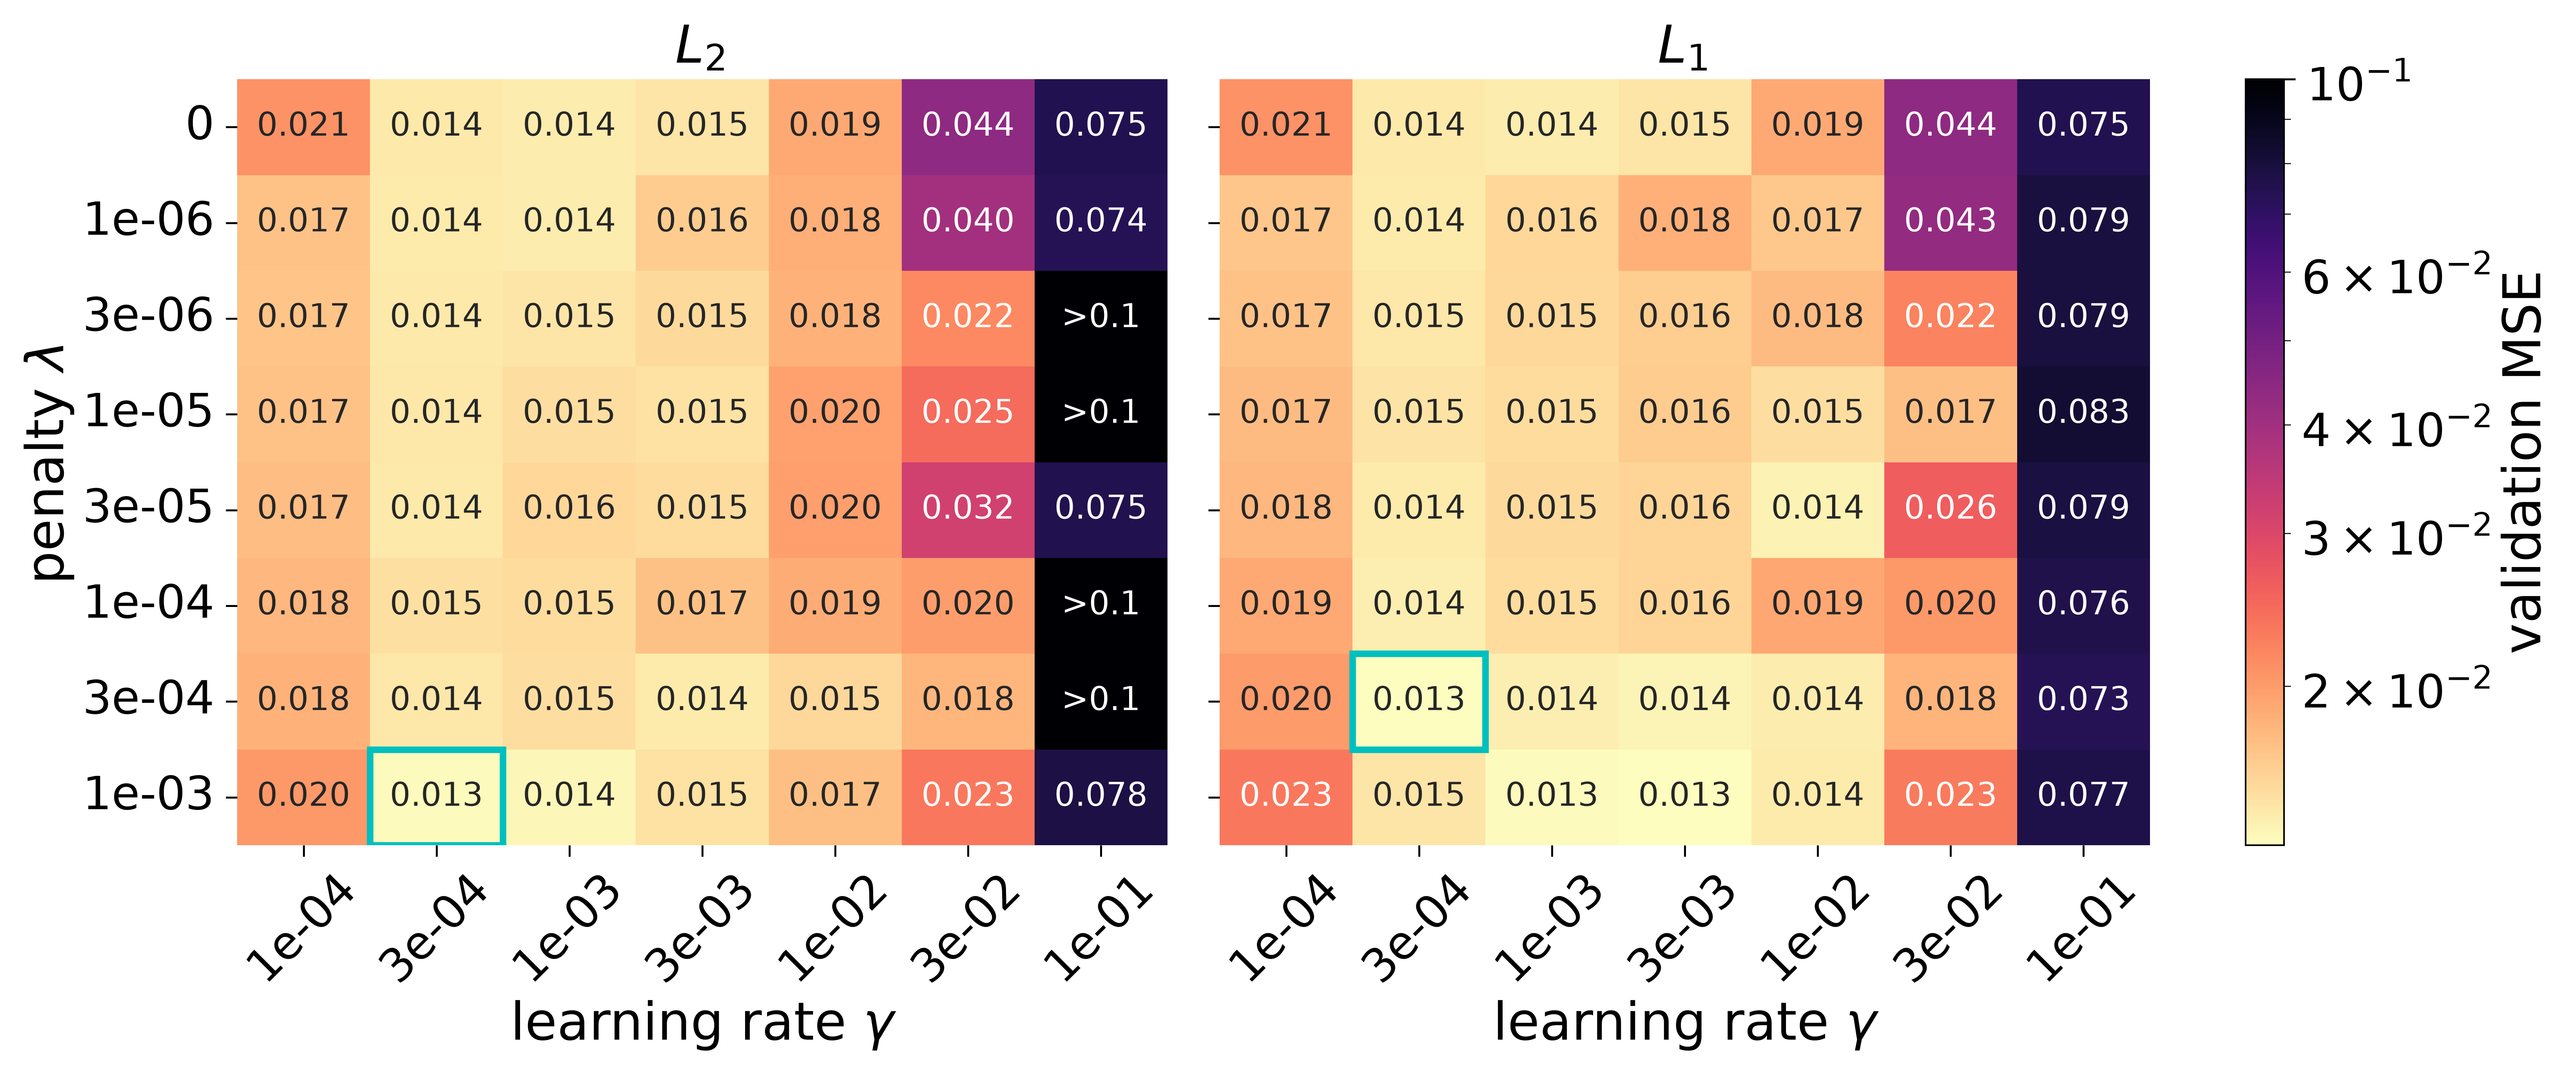

In [13]:
MSE_CAP = 0.1   # above this, the network is no better than predicting the mean
val_mse_mean_d = penalty_sweep["val_mse"].mean(axis=-1)     # average over seeds
best_overall, best_penalized = {}, {}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for n, (ax, norm) in enumerate(zip(axes, NORMS)):
    grid = val_mse_mean_d[n]
    labels = np.where(grid < MSE_CAP, np.char.mod("%.3f", grid), ">0.1")
    sns.heatmap(grid, ax=ax, cmap="magma_r", norm=LogNorm(np.nanmin(val_mse_mean_d), MSE_CAP),
                annot=labels, fmt="", cbar=False,
                xticklabels=[f"{g:.0e}" for g in GAMMAS_D],
                yticklabels=[f"{l:.0e}" if l > 0 else "0" for l in LAMBDAS])
    ax.set(title=rf"$L_{norm[1]}$", xlabel=r"learning rate $\gamma$")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
    
    best_overall[norm] = u.best_cell(grid, lam=LAMBDAS, gamma=GAMMAS_D)
    best_penalized[norm] = u.best_cell(grid[1:], lam=LAMBDAS[1:], gamma=GAMMAS_D)
    i, j = best_overall[norm]["index"]
    ax.add_patch(Rectangle((j, i), 1, 1, fill=False, ec="c",  lw=2))
    print(f"{norm}: best lambda {best_overall[norm]['lam']:.0e}, "
          f"gamma {best_overall[norm]['gamma']:.0e}, "
          f"val MSE {best_overall[norm]['value']:.4f}")
axes[0].set_ylabel(r"penalty $\lambda$")
fig.colorbar(axes[0].collections[0], ax=axes, label="validation MSE")
fig.savefig(FIGURES_PATH / "D-lambda_gamma.pdf")

Comparison with Project 1: Ridge and Lasso chosen by CV vs. the best penalized
networks, all evaluated once on the test set

model                  degree    lambda            test MSE
OLS (Project 1)            12   0.0e+00              0.0093
Ridge (Project 1)          14   4.0e-07              0.0105
Lasso (Project 1)          14   1.0e-08              0.0085
NN, no penalty              -   0.0e+00      0.0165 ± 0.0006
NN, L2                      -   1.0e-03      0.0074 ± 0.0009
NN, L1                      -   3.2e-04      0.0078 ± 0.0009


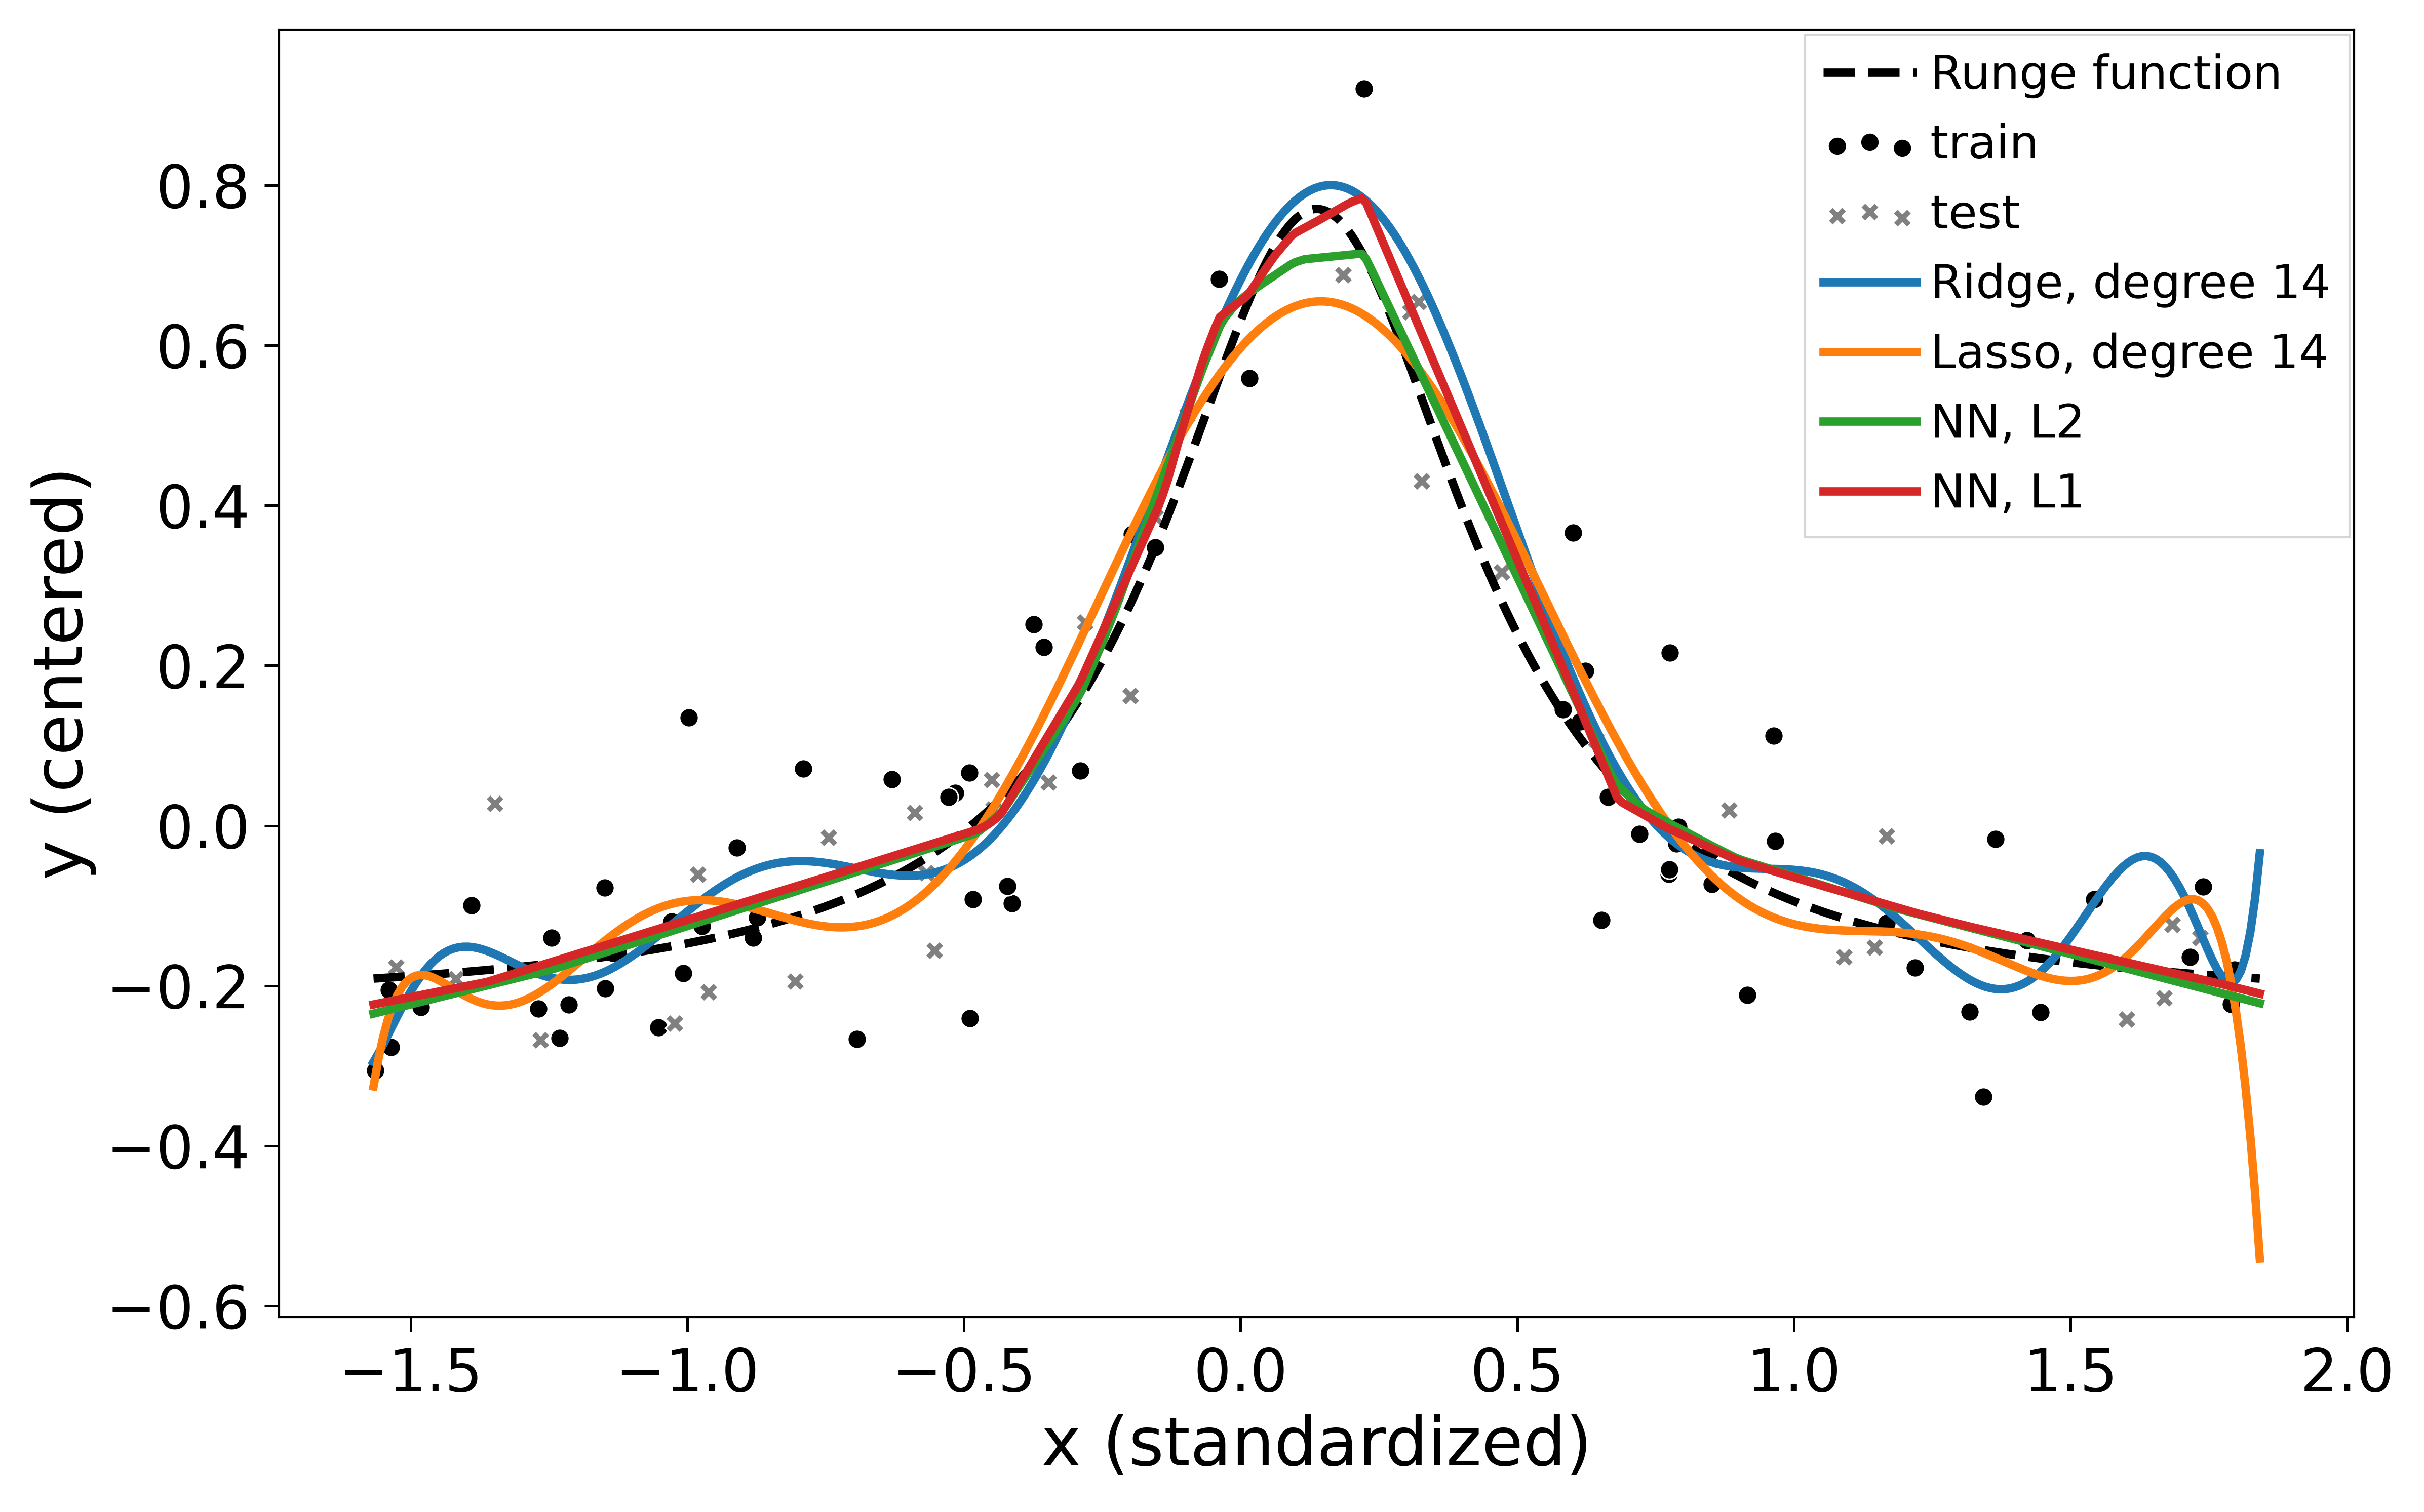

In [14]:
ALPHAS_P1 = np.logspace(-8, 0, 6)
degrees = np.arange(1, MAX_DEGREE + 1)

def compute_ridge_lasso_cv():
    ridge = np.zeros((MAX_DEGREE, len(ALPHAS_P1)))
    lasso = np.zeros_like(ridge)
    for j, alpha in enumerate(ALPHAS_P1):
        ridge[:, j] = u.k_fold_degrees(runge_X_train, runge_y_train, K,
                                       Ridge(alpha=alpha), maxdegree=MAX_DEGREE)
        lasso[:, j] = u.k_fold_degrees(runge_X_train, runge_y_train, K,
                                       Lasso(alpha=alpha, max_iter=100_000), maxdegree=MAX_DEGREE)
    return {"ridge": ridge, "lasso": lasso}

ridge_lasso_cv = u.cached_arrays(RESULTS_PATH / "d_ridge_lasso_cv.npz", compute_ridge_lasso_cv, RERUN)

# For each method: pick (degree, alpha) by CV, refit on training set, evaluate once on test set
benchmarks = {"OLS": {"degree": best_degree, "alpha": 0.0, "model": ols_model, "test_mse": ols_test_mse}}
for name, cv_mse, Model, extra in [("Ridge", ridge_lasso_cv["ridge"], Ridge, {}),
                                   ("Lasso", ridge_lasso_cv["lasso"], Lasso, {"max_iter": 100_000})]:
    best = u.best_cell(cv_mse, degree=degrees, alpha=ALPHAS_P1)
    model = u.poly_model(int(best["degree"]), Model(alpha=best["alpha"], **extra)).fit(runge_X_train, runge_y_train)
    benchmarks[name] = {"degree": int(best["degree"]), "alpha": best["alpha"], "model": model,
                        "test_mse": mse_score(runge_y_test, model.predict(runge_X_test))}

# ==============================================================================

def retrain_penalized_nets(lam, gamma, seeds=SEEDS_D):
    '''Retrain on the whole training set, and return mean and std of the test MSE over seeds'''
    lam1, lam2 = lam
    test_scores, nets = [], []
    for seed in seeds:
        net = NeuralNetwork([1] + [ARCH_WIDTH] * ARCH_DEPTH + [1],
                            [ARCH_ACTIVATION] * ARCH_DEPTH + ["identity"],
                            "mse", lmbd1=lam1, lmbd2=lam2, seed=seed)
        with np.errstate(all="ignore"):
            train(net, runge_X_train, runge_Y_train, method="rmsprop", gamma=gamma,
                  epochs=EPOCHS_D, batch_size=10, seed=seed)
        test_scores.append(mse_score(runge_Y_test, net.predict(runge_X_test)))
        nets.append(net)
    return np.mean(test_scores), np.std(test_scores), nets[0]

best_unpenalized = u.best_cell(val_mse_mean_d[0, 0], gamma=GAMMAS_D)    # lambda = 0 row
nn_settings = {"NN, no penalty": ((0.0, 0.0), best_unpenalized["gamma"]),
               "NN, L2": ((0.0, best_penalized["l2"]["lam"]), best_penalized["l2"]["gamma"]),
               "NN, L1": ((best_penalized["l1"]["lam"], 0.0), best_penalized["l1"]["gamma"])}
nn_results = {name: retrain_penalized_nets(lam, gamma) for name, (lam, gamma) in nn_settings.items()}

print(f"{'model':<22}{'degree':>7}{'lambda':>10}{'test MSE':>20}")
for name, info in benchmarks.items():
    print(f"{name + ' (Project 1)':<22}{info['degree']:>7}{info['alpha']:>10.1e}{info['test_mse']:>20.4f}")
for name, (lam, _) in nn_settings.items():
    mean, std, _ = nn_results[name]
    print(f"{name:<22}{'-':>7}{max(lam):>10.1e}{mean:>12.4f} ± {std:.4f}")
    
# ==============================================================================

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(grid_x_std, runge_true_curve, "k--", label="Runge function")
sns.scatterplot(x=runge_x_train, y=runge_y_train, s=20, color="k", label="train", ax=ax)
sns.scatterplot(x=runge_x_test, y=runge_y_test, s=20, color="gray", marker="X", label="test", ax=ax)
for name in ("Ridge", "Lasso"):
    info = benchmarks[name]
    sns.lineplot(x=grid_x_std, y=info["model"].predict(grid_x_std.reshape(-1, 1)),
                 label=f"{name}, degree {info['degree']}", ax=ax)
for name in ("NN, L2", "NN, L1"):
    sns.lineplot(x=grid_x_std, y=nn_results[name][2].predict(to_column(grid_x_std)).ravel(),
                 label=name, ax=ax)
ax.set(xlabel="x (standardized)", ylabel="y (centered)")
ax.legend(loc="upper right", fontsize=11)
fig.savefig(FIGURES_PATH / "D-NN_vs_Ridge_Lasso.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part e)** Classification analysis

</div>

Load mnist dataset, scaled and centered. Split into train, val, and test sets.

In [15]:
x_train, y_train, x_test, y_test = load_mnist(DATA_PATH)
x_fit, x_val, y_fit, y_val = train_val_split(x_train, y_train, val_size=0.25, seed=SEED, stratify=False)
Y_fit, Y_val = one_hot(y_fit), one_hot(y_val)   # train needs (n, 10)

print("Train: ", x_fit.shape, y_fit.shape)
print("Val:   ", x_val.shape, y_val.shape)
print("Test:  ", x_test.shape, y_test.shape)

Train:  (45000, 784) (45000,)
Val:    (15000, 784) (15000,)
Test:   (10000, 784) (10000,)


Logistic regression.

To save the model from the run, we need to save it in form of $W$ and $b$, such
that instead of predicting with `model.predict(x_test)`, we instead predict the
traditional way: $y_\mathrm{pred}=x_\mathrm{test}\cdot \boldsymbol{W}^\top + b$.

This has been tested against saving the model directly, and returns the same
accuracy.

In [16]:
def compute_logistic_regression():
    model = LogisticRegression(solver="saga", max_iter=1000, random_state=42)
    model.fit(x_train, y_train)
    return {"coef": model.coef_, "intercept": model.intercept_} # shapes (10, 784) and (10,)

logreg = u.cached_arrays(RESULTS_PATH / "e_logreg_params.npz", compute_logistic_regression, RERUN)

logreg_scores = x_test @ logreg["coef"].T + logreg["intercept"]
logreg_predictions = np.argmax(logreg_scores, axis=1)
logreg_accuracy = accuracy(y_test, logreg_predictions)
print(f"Model Accuracy: {logreg_accuracy:.4f}")

Model Accuracy: 0.9257


Train one classifier on the fit set. Returns the network and its per-epoch history

In [17]:
def accuracy_metric(net, X, Y_onehot):
    '''Accuracy of a net on X. Targets are one-hot because train needs them that way.'''
    return accuracy(np.argmax(Y_onehot, axis=1), np.argmax(net.predict(X), axis=1))


def run_one_mnist(activation, hidden, lam, gamma, epochs, batch_size, seed, method="adam"):
    '''
    activation : hidden-layer activation, e.g. "relu"
    hidden     : hidden layer sizes, e.g. (128, 64); () means no hidden layer (= logistic regression)
    lam        : (lambda1, lambda2) for the L1 and L2 penalties
    '''
    l1, l2 = lam
    sizes = [x_fit.shape[1], *hidden, 10]       # 10 output nodes
    acts = [activation] * len(hidden) + ["softmax"]
    net = NeuralNetwork(sizes, acts, "cross_entropy", lmbd1=l1, lmbd2=l2, seed=seed)
    history = train(net, x_fit, Y_fit, method=method, gamma=gamma, epochs=epochs,
                    batch_size=batch_size, seed=seed, X_val=x_val, Y_val=Y_val,
                    metric=accuracy_metric)
    return net, history

Learning curves: No hidden layer (= logistic regression) vs. one hidden layer

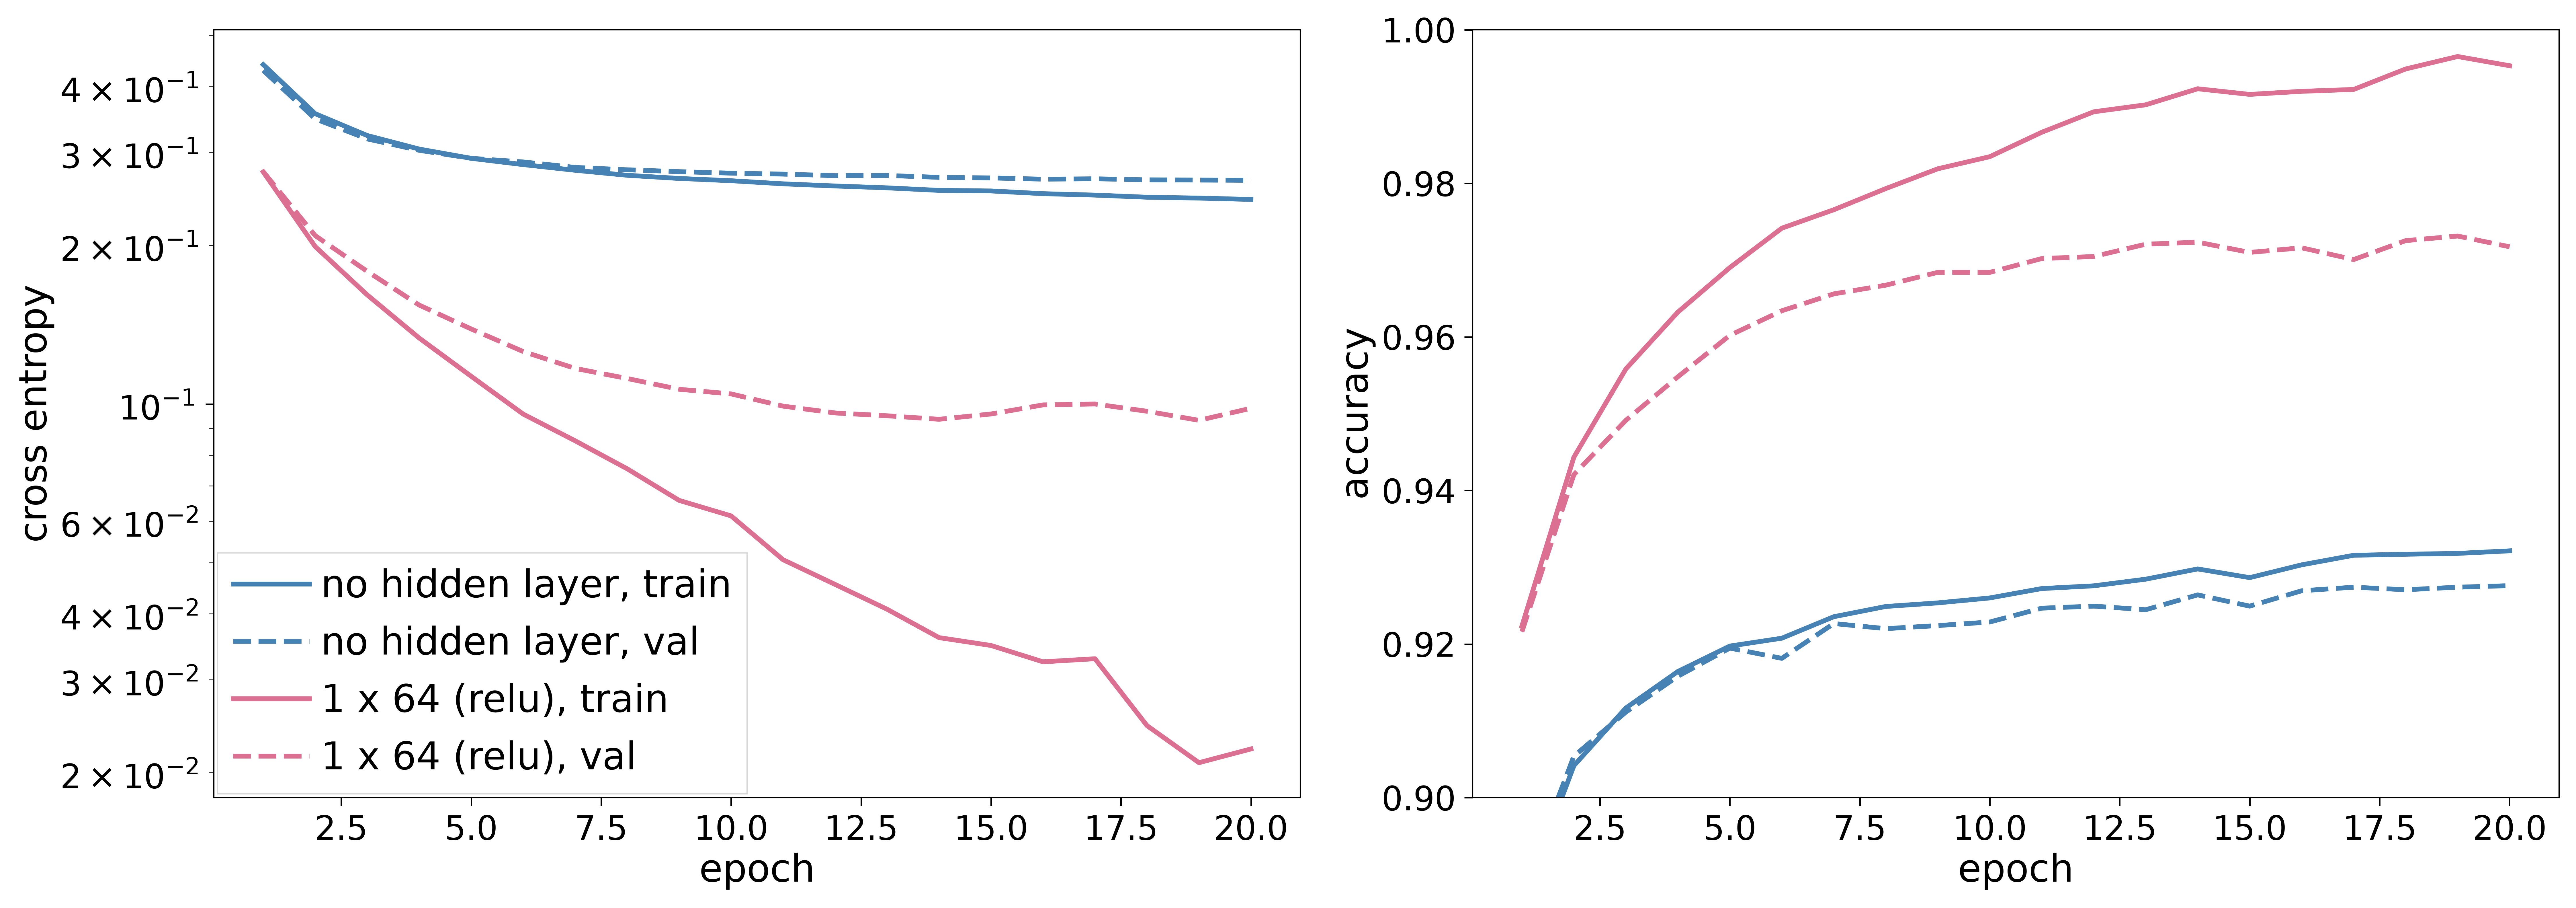

In [18]:
EPOCHS_BASE, BATCH_E = 20, 128
BASELINES = {"no hidden layer": ((), "relu"),   # label: (hidden, activation)
             "1 x 64 (relu)": ((64,), "relu")}

def compute_baseline_curves():
    names = ("train_cost", "val_cost", "train_accuracy", "val_accuracy")
    curves = {name: np.zeros((len(BASELINES), EPOCHS_BASE)) for name in names}
    for i, (hidden, activation) in enumerate(BASELINES.values()):
        _, history = run_one_mnist(activation, hidden, (0.0, 0.0), 1e-3, 
                                   EPOCHS_BASE, BATCH_E, SEED)
        curves["train_cost"][i], curves["val_cost"][i] = history["train_cost"], history["val_cost"]
        curves["train_accuracy"][i], curves["val_accuracy"][i] = history["train_metric"], history["val_metric"]
    return curves

baseline = u.cached_arrays(RESULTS_PATH / "e_baseline_curves.npz", compute_baseline_curves, RERUN)

epochs = np.arange(1, EPOCHS_BASE + 1)
colors = ["steelblue", "palevioletred"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.3))
for i, label in enumerate(BASELINES):
    color = colors[i]
    for split, linestyle in (("train", "-"), ("val", "--")):
        axes[0].plot(epochs, baseline[f"{split}_cost"][i], linestyle, color=color, label=f"{label}, {split}")
        axes[1].plot(epochs, baseline[f"{split}_accuracy"][i], linestyle, color=color, label=f"{label}, {split}")
axes[0].set(xlabel="epoch", ylabel="cross entropy", yscale="log")
axes[1].set(xlabel="epoch", ylabel="accuracy", ylim=(0.9, 1.0))
axes[0].legend(loc="lower left")
fig.savefig(FIGURES_PATH / "E-baseline_curves.pdf")

Validation accuracy over learning rate and penalty strength, for $\ell_2$ and $\ell_1$

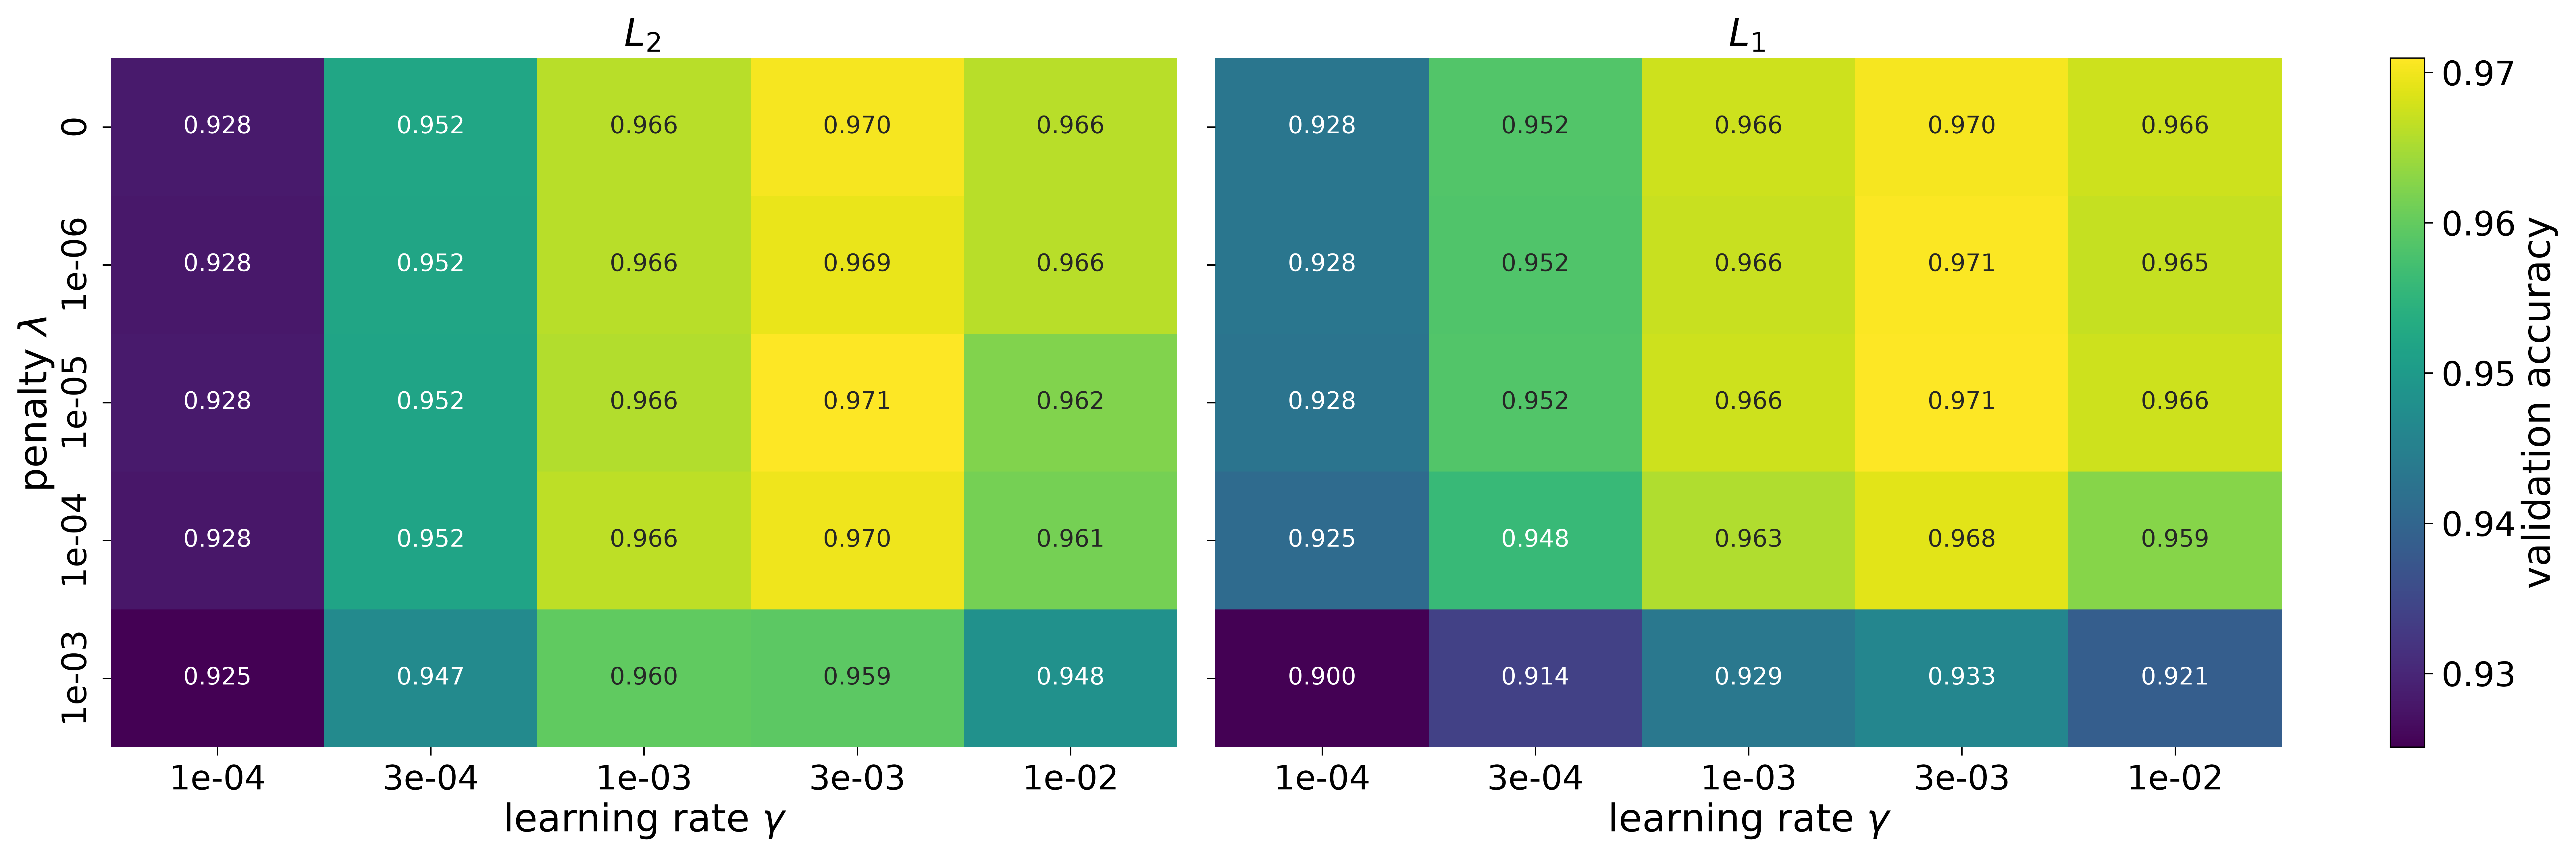

In [29]:

HIDDEN_E, ACTIVATION_E = (64,), "relu"
GAMMAS_E = np.geomspace(1e-4, 1e-2, 5)
LAMBDAS_E = np.array([0, 1e-6, 1e-5, 1e-4, 1e-3])
SEEDS_E = [0, 1, 2]
EPOCHS_E = 10

def compute_gamma_lambda_sweep():
    shape = (len(NORMS), len(LAMBDAS_E), len(GAMMAS_E), len(SEEDS_E))
    val_accuracy = np.full(shape, np.nan)
    for n, l, g, s in np.ndindex(shape):
        lam = (LAMBDAS_E[l], 0.0) if NORMS[n] == "l1" else (0.0, LAMBDAS_E[l])
        with np.errstate(all="ignore"):
            _, history = run_one_mnist(ACTIVATION_E, HIDDEN_E, lam, GAMMAS_E[g],
                                       EPOCHS_E, BATCH_E, SEEDS_E[s])
        val_accuracy[n, l, g, s] = history["val_metric"][-1]
    return {"val_accuracy": val_accuracy}

gamma_lambda = u.cached_arrays(RESULTS_PATH / "e_gamma_lambda_sweep.npz", compute_gamma_lambda_sweep, RERUN)
val_accuracy_mean = gamma_lambda["val_accuracy"].mean(axis=-1)  # average over seeds

best_gamma_lambda = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, norm, grid in zip(axes, NORMS, val_accuracy_mean):
    sns.heatmap(grid, ax=ax, annot=True, fmt=".3f", cmap="viridis", cbar=False,
                xticklabels=[f"{g:.0e}" for g in GAMMAS_E],
                yticklabels=[f"{l:.0e}" if l > 0 else "0" for l in LAMBDAS_E])
    ax.set(title=f"$L_{norm[1]}$", xlabel=r"learning rate $\gamma$")
    best_gamma_lambda[norm] = u.best_cell(grid, smallest=False, lam=LAMBDAS_E, gamma=GAMMAS_E)
axes[0].set_ylabel(r"penalty $\lambda$")
fig.colorbar(axes[0].collections[0], ax=axes, label="validation accuracy")
fig.savefig(FIGURES_PATH / "E-gamma_lambda.pdf")

Validation accuracy over depth and width. $\gamma$ and $\lambda$ fixed to the best from the sweep above

leaky_relu, 1 hidden layers x 128 nodes


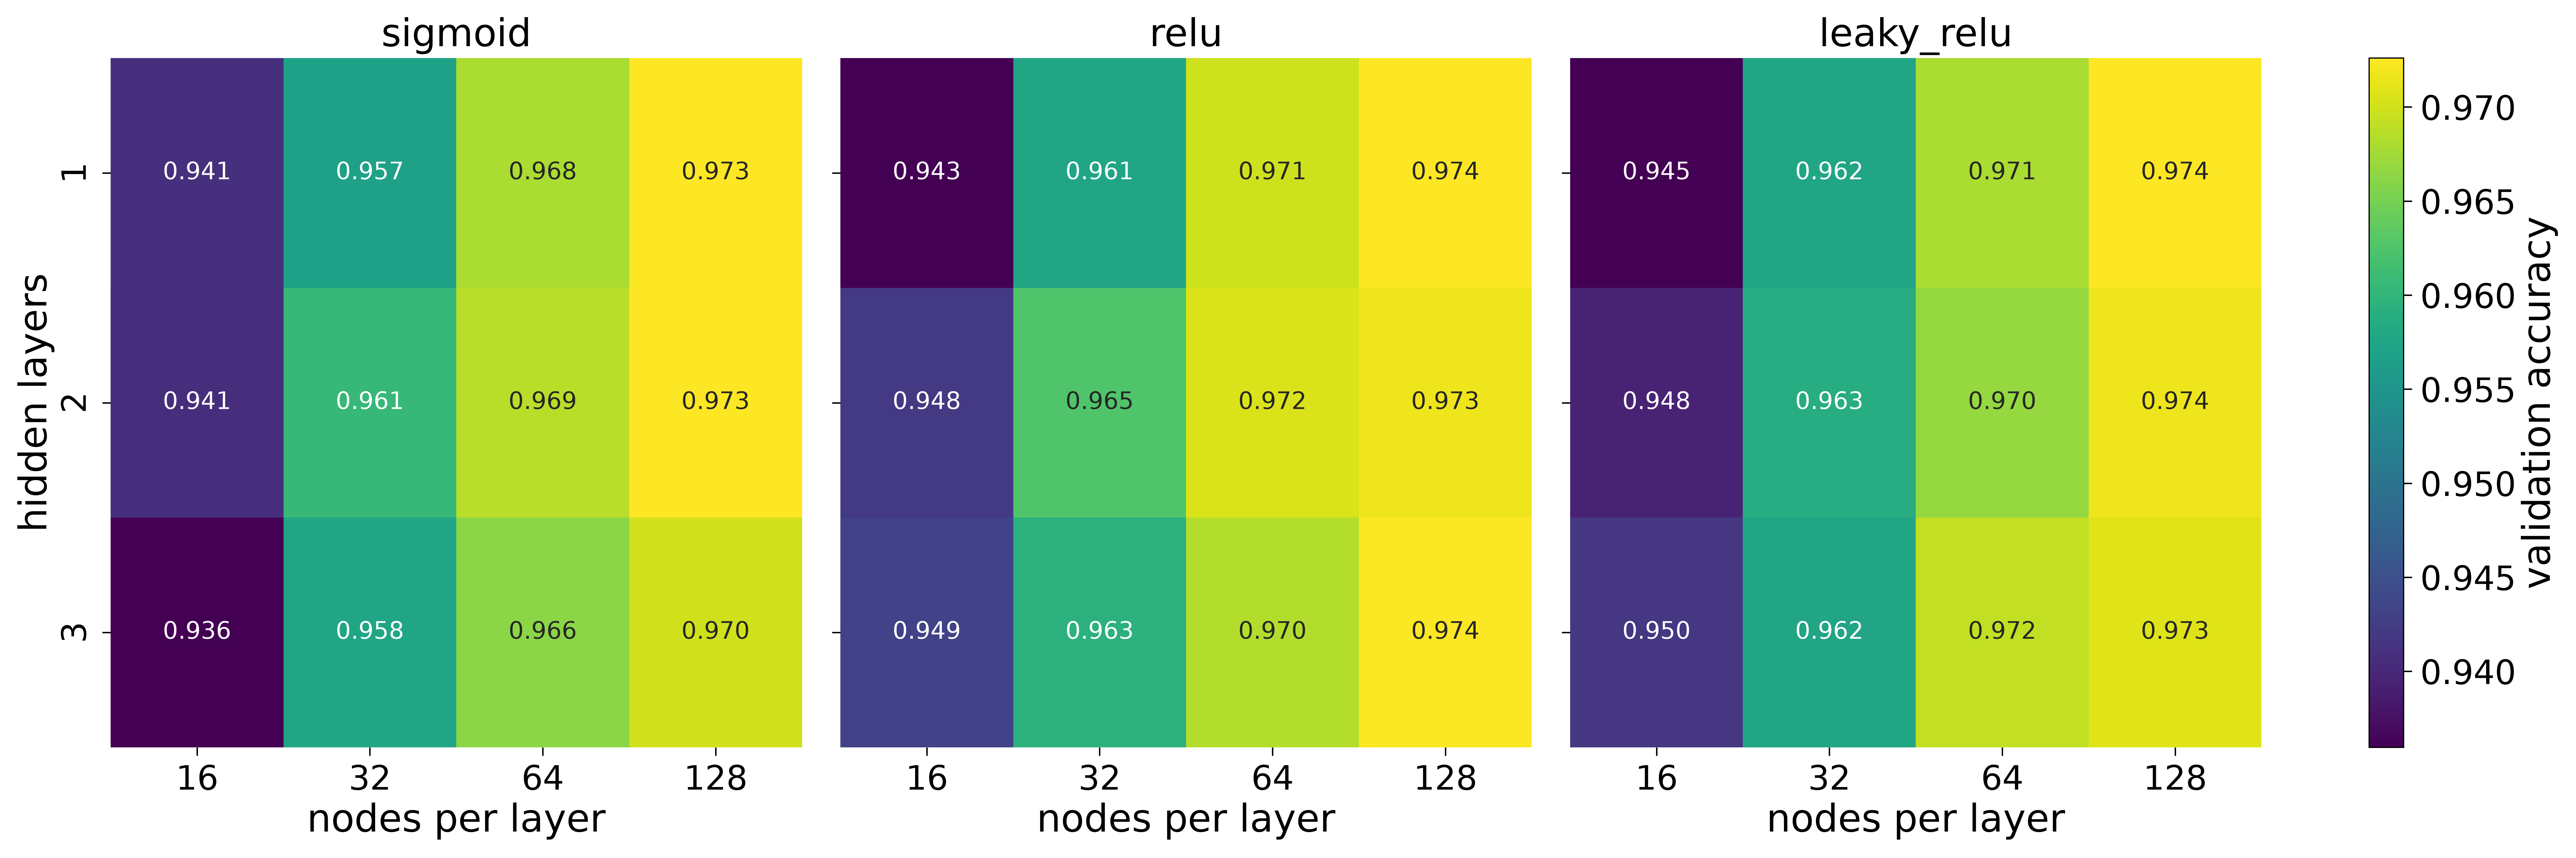

In [27]:
ACTIVATIONS_E = ["sigmoid", "relu", "leaky_relu"]
DEPTHS_E = [1, 2, 3]
WIDTHS_E = [16, 32, 64, 128]
winner = max(best_gamma_lambda, key=lambda norm: best_gamma_lambda[norm]["value"])
gamma_best = best_gamma_lambda[winner]["gamma"]
lam_best = (best_gamma_lambda[winner]["lam"], 0.0) if winner == "l1" else (0.0, best_gamma_lambda[winner]["lam"])

def compute_architecture_sweep():
    shape = (len(ACTIVATIONS_E), len(DEPTHS_E), len(WIDTHS_E), len(SEEDS_E))
    val_accuracy = np.full(shape, np.nan)
    for a, d, w, s in np.ndindex(shape):
        hidden = (WIDTHS_E[w],) * DEPTHS_E[d]
        with np.errstate(all="ignore"):
            _, history = run_one_mnist(ACTIVATIONS_E[a], hidden, lam_best, gamma_best,
                                       epochs=EPOCHS_E, batch_size=BATCH_E, seed=SEEDS_E[s])
        val_accuracy[a, d, w, s] = history["val_metric"][-1]
    return {"val_accuracy": val_accuracy}

architecture = u.cached_arrays(RESULTS_PATH / "e_architecture_sweep.npz", compute_architecture_sweep, RERUN)
val_accuracy_mean = architecture["val_accuracy"].mean(axis=-1)  # average over seeds

best_architecture = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, activation, grid in zip(axes, ACTIVATIONS_E, val_accuracy_mean):
    sns.heatmap(grid, ax=ax, annot=True, fmt=".3f", cmap="viridis", cbar=False,
                xticklabels=[w for w in WIDTHS_E],
                yticklabels=[d for d in DEPTHS_E])
    ax.set(title=activation, xlabel="nodes per layer")
    best_architecture[activation] = u.best_cell(grid, smallest=False, depth=DEPTHS_E, width=WIDTHS_E)
axes[0].set_ylabel("hidden layers")
fig.colorbar(axes[0].collections[0], ax=axes, label="validation accuracy")
fig.savefig(FIGURES_PATH / "E-architectures.pdf")

ARCH_ACTIVATION = max(best_architecture, key=lambda activation: best_architecture[activation]["value"])
ARCH_WIDTH = best_architecture[ARCH_ACTIVATION]["width"]
ARCH_DEPTH = best_architecture[ARCH_ACTIVATION]["depth"]
print(f"{ARCH_ACTIVATION}, {ARCH_DEPTH} hidden layers x {ARCH_WIDTH} nodes")

Validation accuracy per optimizer across learning rates

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part f)** Various algorithms

</div>